In [1]:
# ================================================================
# CRDL COMPONENT 3
# C3-09 | SECTION 0
# PHYSICAL EVIDENCE GATE V2.0
# ================================================================

from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone

import os
import re
import json
import csv
import math
import hashlib
import uuid
import statistics

from collections import Counter

import numpy as np
from PIL import Image
from scipy.io import whosmat

# ------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------

drive.mount('/content/drive')

# ------------------------------------------------
# 2. Define project locations
# ------------------------------------------------

ROOT = Path('/content/drive/MyDrive')

PROJECT = (
    ROOT /
    'crdl_experiments' /
    'component3_fresh_v1'
)

RAW = ROOT / 'manushi_research_data'

P440 = RAW / 'Pothole440-main'

FAN = RAW / 'fan_stereo_pothole'

PREVIOUS = (
    PROJECT /
    '07_evaluation' /
    'C3-08_section14_P440_PAIRED_MODEL_AUDIT_20261021T021139_961672Z'
)

# ------------------------------------------------
# 3. Unique experiment identifier
# ------------------------------------------------

STAMP = (
    datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    + '_'
    + uuid.uuid4().hex[:8]
)

OUT = (
    PROJECT /
    '07_evaluation' /
    ('C3-09_physical_evidence_gate_v2_' + STAMP)
)

VERSION = 'C3-09.2.0'

# ------------------------------------------------
# 4. Verify existing folders
# ------------------------------------------------

assert PROJECT.is_dir(), (
    f'Existing Component 3 project missing: {PROJECT}'
)

assert P440.joinpath('train').is_dir(), (
    f'P440 TRAIN source missing: {P440}'
)

assert PREVIOUS.is_dir(), (
    f'Existing C3-08 audit missing: {PREVIOUS}'
)

# Never overwrite an existing experiment.
OUT.mkdir(parents=True, exist_ok=False)

# ------------------------------------------------
# 5. Reusable saving functions
# ------------------------------------------------

def write_json(name, obj):
    (OUT / name).write_text(
        json.dumps(obj, indent=2, default=str),
        encoding='utf-8'
    )


def digest(path):
    h = hashlib.sha256()

    with Path(path).open('rb') as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(block)

    return h.hexdigest()


def write_csv(name, rows, fields):
    with (OUT / name).open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:
        writer = csv.DictWriter(
            f,
            fieldnames=fields
        )
        writer.writeheader()
        writer.writerows(rows)

# ------------------------------------------------
# 6. Freeze experiment configuration
# ------------------------------------------------

FROZEN = {
    'version': VERSION,
    'time_utc': STAMP,
    'project': str(PROJECT),
    'raw_source': str(RAW),

    'p440_used_split': 'train only',

    'fan_used_splits': [
        'dataset1',
        'dataset3'
    ],

    'protected': [
        'P440 val/test',
        'Fan dataset2',
        'frozen 399',
        'Phase13',
        'holdout'
    ],

    'new_model_training': False,
    'metric_units_certified': False,

    'previous_section14_folder': str(PREVIOUS)
}

write_json(
    'configuration.json',
    FROZEN
)

print("=" * 65)
print("CRDL COMPONENT 3 — C3-09 INITIALIZATION")
print("=" * 65)

print("VERSION:", VERSION)
print("PROJECT:", PROJECT)
print("OUTPUT:", OUT)

print("ROOTS VERIFIED")
print("NO PREVIOUS FILES ALTERED")
print("=" * 65)

Mounted at /content/drive
CRDL COMPONENT 3 — C3-09 INITIALIZATION
VERSION: C3-09.2.0
PROJECT: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1
OUTPUT: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662
ROOTS VERIFIED
NO PREVIOUS FILES ALTERED


C3-09 SECTION 1 — PAIRED MODEL AUDIT VERIFICATION
Project: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1
Previous audit: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-08_section14_P440_PAIRED_MODEL_AUDIT_20261021T021139_961672Z
Current output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662

SECTION 14 FILE INTEGRITY: PASS
SECTION 13 SOURCE LINEAGE: PASS


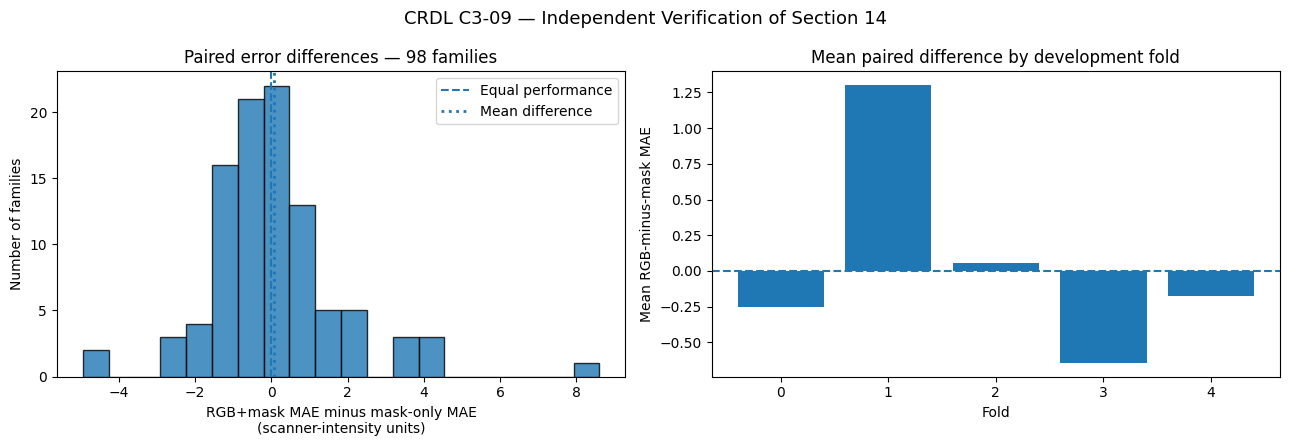


CRDL C3-09 SECTION 1 — VERIFIED PAIRED MODEL AUDIT
Verified paired families: 98
RGB wins / mask wins / ties: 55 43 0
RGB MAE (intensity): 12.6871
Mask MAE (intensity): 12.6204
Mean RGB-minus-mask MAE: 0.0667
Median difference: -0.1577
Family bootstrap 95% interval: [-0.2832, 0.4322]
Fold-resampling 95% interval: [-0.405, 0.7277]
Exploratory sign-test p-value: 0.2664
Mean without three largest RGB losses: -0.1138

FOLD DETAILS:
Fold 0 | n=20 | mean difference=-0.2493
Fold 1 | n=20 | mean difference=1.3006
Fold 2 | n=20 | mean difference=0.0531
Fold 3 | n=19 | mean difference=-0.6419
Fold 4 | n=19 | mean difference=-0.1767

SECTION 13 SOURCE INTEGRITY: PASS
SECTION 14 FILE INTEGRITY: PASS
PAIRED FAMILY VALIDATION: PASS
RGB SUPERIORITY ESTABLISHED: NO
MASK SUPERIORITY ESTABLISHED: NO
INDEPENDENT SCENE VALIDATION: NO
VERIFIED PHYSICAL UNITS: NO
ADDITIONAL TRAINING PERFORMED: NO

Saved reports:
 - /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evid

In [3]:
# ================================================================
# CRDL COMPONENT 3
# C3-09 | SECTION 1
# VERIFIED P440 PAIRED MODEL AUDIT
# ================================================================
#
# PURPOSE:
# Independently verify C3-08 Section 14.
#
# INPUT:
# Existing 98-family out-of-fold predictions
# and Section 13 provenance.
#
# OUTPUT:
# Versioned verification reports inside C3-09.
#
# IMPORTANT:
# No training.
# No physical-unit claims.
# No modification to earlier experiments.
# ================================================================

from pathlib import Path
from collections import Counter
from scipy.stats import binomtest

import hashlib
import json
import csv
import numpy as np
import matplotlib.pyplot as plt


# ================================================================
# 1. VERIFY C3-09 ENVIRONMENT
# ================================================================

assert 'PROJECT' in globals(), (
    "Run C3-09 Section 0 first."
)

assert 'PREVIOUS' in globals(), (
    "Previous audit path not initialized."
)

assert 'OUT' in globals(), (
    "Output folder not initialized."
)

assert PROJECT.is_dir()
assert PREVIOUS.is_dir()
assert OUT.is_dir()

print("=" * 65)
print("C3-09 SECTION 1 — PAIRED MODEL AUDIT VERIFICATION")
print("=" * 65)

print("Project:", PROJECT)
print("Previous audit:", PREVIOUS)
print("Current output:", OUT)


# ================================================================
# 2. VERIFY CRYPTOGRAPHIC FILE INTEGRITY
# ================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def read_checksums(folder):

    checksum_file = folder / "checksums.sha256"

    assert checksum_file.is_file(), (
        f"Missing checksum file: {checksum_file}"
    )

    checksums = {}

    for line in checksum_file.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        digest_value, filename = line.split(
            None, 1
        )

        filename = filename.strip().lstrip("*")

        assert filename not in checksums, (
            f"Duplicate checksum entry: {filename}"
        )

        checksums[filename] = digest_value.lower()

    return checksums


def verify_file(folder, filename, checksums):

    path = folder / filename

    assert path.is_file(), (
        f"Required source file missing: {path}"
    )

    assert filename in checksums, (
        f"Missing checksum for: {filename}"
    )

    actual_hash = sha256_file(path)

    expected_hash = checksums[filename]

    assert actual_hash == expected_hash, (
        f"CHECKSUM MISMATCH: {filename}"
    )

    return actual_hash


# Verify Section 14 saved artifacts.

section14_checksums = read_checksums(PREVIOUS)

section14_hashes = {}

for filename in [
    "paired_family_predictions.csv",
    "paired_model_evidence.json",
    "rgb_contribution_reliability.png"
]:

    section14_hashes[filename] = verify_file(
        PREVIOUS,
        filename,
        section14_checksums
    )

print("\nSECTION 14 FILE INTEGRITY: PASS")


# ================================================================
# 3. LOAD ORIGINAL SECTION 14 EVIDENCE
# ================================================================

evidence_file = (
    PREVIOUS / "paired_model_evidence.json"
)

predictions_file = (
    PREVIOUS / "paired_family_predictions.csv"
)

with evidence_file.open(
    "r",
    encoding="utf-8"
) as f:

    evidence = json.load(f)


with predictions_file.open(
    "r",
    newline="",
    encoding="utf-8"
) as f:

    paired_rows = list(csv.DictReader(f))


assert evidence["stage"] == "C3-08_SECTION14"

assert evidence["family_count"] == 98

assert len(paired_rows) == 98

assert evidence["metric_depth_supervision"] is False


# ================================================================
# 4. VERIFY ORIGINAL SECTION 13 SOURCE LINEAGE
# ================================================================

RUN_NAME = (
    "C3-08_section13_P440_RELATIVE_INTENSITY_ML_"
    "20261021T014247_895190Z"
)

RUN13 = PROJECT / "05_training_runs" / RUN_NAME

DATA13 = PROJECT / "04_geometry_targets" / RUN_NAME

assert RUN13.is_dir(), (
    f"Missing Section 13 training run: {RUN13}"
)

assert DATA13.is_dir(), (
    f"Missing Section 13 geometry data: {DATA13}"
)

expected_source_hashes = evidence["source_hashes"]

original_sources = {

    "oof": (
        RUN13 / "per_family_oof.csv"
    ),

    "report": (
        RUN13 / "ablation_report.json"
    ),

    "folds": (
        DATA13 / "family_proxy_folds.json"
    ),

    "protocol": (
        DATA13 / "locked_protocol.json"
    )
}

verified_original_sources = {}

for source_name, source_path in original_sources.items():

    assert source_path.is_file(), (
        f"Missing source file: {source_path}"
    )

    actual_hash = sha256_file(source_path)

    expected_hash = expected_source_hashes[source_name]

    assert actual_hash == expected_hash, (
        f"SECTION 13 SOURCE HASH MISMATCH: {source_name}"
    )

    verified_original_sources[source_name] = actual_hash

print("SECTION 13 SOURCE LINEAGE: PASS")


# ================================================================
# 5. VALIDATE PAIRED FAMILY STRUCTURE
# ================================================================

families = [
    row["family"]
    for row in paired_rows
]

folds = [
    int(row["fold"])
    for row in paired_rows
]

assert len(set(families)) == 98, (
    "Duplicate family IDs detected."
)

assert set(folds) == {0, 1, 2, 3, 4}, (
    "Unexpected fold assignment."
)


# ================================================================
# 6. EXTRACT PAIRED MODEL ERRORS
# ================================================================

rgb_mae = np.array([

    float(row["rgb_mae"])

    for row in paired_rows

], dtype=np.float64)


mask_mae = np.array([

    float(row["mask_mae"])

    for row in paired_rows

], dtype=np.float64)


saved_differences = np.array([

    float(row["rgb_minus_mask_mae"])

    for row in paired_rows

], dtype=np.float64)


# Independently recalculate paired differences.
differences = rgb_mae - mask_mae


assert np.all(
    np.isfinite(rgb_mae)
)

assert np.all(
    np.isfinite(mask_mae)
)

assert np.all(
    np.isfinite(differences)
)

assert np.allclose(
    differences,
    saved_differences,
    rtol=0,
    atol=1e-6
), "Saved paired differences disagree with original MAEs."


# ================================================================
# 7. RECALCULATE ERROR STATISTICS
# ================================================================

n_families = len(differences)

rgb_mean_mae = float(
    np.mean(rgb_mae)
)

mask_mean_mae = float(
    np.mean(mask_mae)
)

mean_difference = float(
    np.mean(differences)
)

median_difference = float(
    np.median(differences)
)


# Negative difference means RGB is better.
rgb_wins = int(
    np.sum(differences < 0)
)

# Positive difference means mask is better.
mask_wins = int(
    np.sum(differences > 0)
)

ties = int(
    np.sum(differences == 0)
)


assert (
    rgb_wins + mask_wins + ties
) == n_families


assert np.isclose(
    rgb_mean_mae,
    evidence["rgb_mean_MAE_intensity"],
    atol=1e-6
)

assert np.isclose(
    mask_mean_mae,
    evidence["mask_mean_MAE_intensity"],
    atol=1e-6
)

assert np.isclose(
    mean_difference,
    evidence["mean_rgb_minus_mask"],
    atol=1e-6
)

assert (
    rgb_wins,
    mask_wins,
    ties
) == (
    evidence["rgb_wins"],
    evidence["mask_wins"],
    evidence["ties"]
)


# ================================================================
# 8. FAMILY BOOTSTRAP CONFIDENCE INTERVAL
# ================================================================

SEED = 20261021

N_BOOTSTRAPS = 20000

rng = np.random.default_rng(SEED)


# Sample complete families with replacement.
bootstrap_indices = rng.integers(

    low=0,

    high=n_families,

    size=(
        N_BOOTSTRAPS,
        n_families
    )
)


bootstrap_mean_differences = (

    differences[bootstrap_indices].mean(axis=1)

)


family_ci = np.percentile(

    bootstrap_mean_differences,

    [2.5, 97.5]

)


assert np.allclose(
    family_ci,
    evidence["family_bootstrap_95ci"],
    atol=1e-6
)


# ================================================================
# 9. EXPLORATORY PAIRED SIGN TEST
# ================================================================

sign_test = binomtest(

    k=rgb_wins,

    n=rgb_wins + mask_wins,

    p=0.5,

    alternative="two-sided"
)

sign_p = float(sign_test.pvalue)


assert np.isclose(
    sign_p,
    evidence["sign_test_p_exploratory"],
    atol=1e-6
)


# ================================================================
# 10. FOLD-LEVEL ERROR STABILITY
# ================================================================

fold_results = []

for fold_id in range(5):

    values = np.array([

        float(row["rgb_minus_mask_mae"])

        for row in paired_rows

        if int(row["fold"]) == fold_id

    ])

    assert len(values) > 0

    fold_results.append({

        "fold": fold_id,

        "n": len(values),

        "mean_rgb_minus_mask":
            float(np.mean(values)),

        "rgb_wins":
            int(np.sum(values < 0)),

        "mask_wins":
            int(np.sum(values > 0))
    })


fold_means = np.array([

    row["mean_rgb_minus_mask"]

    for row in fold_results

])


fold_sizes = np.array([

    row["n"]

    for row in fold_results

])


assert sum(fold_sizes) == 98


# ================================================================
# 11. EXPLORATORY FOLD RESAMPLING
# ================================================================

# There are only five folds.
# This is a sensitivity calculation,
# NOT independent-scene validation.

fold_bootstrap_means = []

for _ in range(N_BOOTSTRAPS):

    selected_folds = rng.integers(

        low=0,

        high=5,

        size=5
    )

    sampled_mean = np.average(

        fold_means[selected_folds],

        weights=fold_sizes[selected_folds]

    )

    fold_bootstrap_means.append(
        float(sampled_mean)
    )


fold_ci = np.percentile(

    fold_bootstrap_means,

    [2.5, 97.5]

)


assert np.allclose(
    fold_ci,
    evidence["fold_resampling_95ci_exploratory"],
    atol=1e-6
)


# ================================================================
# 12. FAILURE-CASE SENSITIVITY ANALYSIS
# ================================================================

# Remove three largest positive RGB-minus-mask differences
# ONLY for a reported exploratory sensitivity analysis.
# Do not actually delete or exclude these observations
# from the main research result.

sorted_differences = np.sort(differences)

mean_without_three_largest_losses = float(

    np.mean(sorted_differences[:-3])

)


assert np.isclose(

    mean_without_three_largest_losses,

    evidence["mean_difference_without_three_largest_losses"],

    atol=1e-6
)


largest_rgb_failures = sorted(

    paired_rows,

    key=lambda row:
        float(row["rgb_minus_mask_mae"]),

    reverse=True

)[:5]


largest_rgb_gains = sorted(

    paired_rows,

    key=lambda row:
        float(row["rgb_minus_mask_mae"])

)[:5]


# ================================================================
# 13. VERIFY CONFIDENCE INTERVAL INTERPRETATION
# ================================================================

family_ci_crosses_zero = bool(

    family_ci[0] <= 0 <= family_ci[1]

)

fold_ci_crosses_zero = bool(

    fold_ci[0] <= 0 <= fold_ci[1]

)

rgb_superiority_established = False

mask_superiority_established = False


# No statistically justified superiority claim.
assert family_ci_crosses_zero

assert fold_ci_crosses_zero


# ================================================================
# 14. SAVE RECALCULATED RESEARCH EVIDENCE
# ================================================================

verified_report = {

    "milestone":
        "C3-09_SECTION1",

    "previous_stage":
        "C3-08_SECTION14",

    "target":
        "UNVERIFIED_SCANNER_INTENSITY_CONTRAST",

    "n_families":
        n_families,

    "rgb_mean_MAE_intensity":
        rgb_mean_mae,

    "mask_mean_MAE_intensity":
        mask_mean_mae,

    "mean_rgb_minus_mask_MAE":
        mean_difference,

    "median_rgb_minus_mask_MAE":
        median_difference,

    "rgb_wins":
        rgb_wins,

    "mask_wins":
        mask_wins,

    "ties":
        ties,

    "family_bootstrap_95ci":
        [float(x) for x in family_ci],

    "fold_resampling_95ci_exploratory":
        [float(x) for x in fold_ci],

    "exploratory_sign_test_p":
        sign_p,

    "family_ci_crosses_zero":
        family_ci_crosses_zero,

    "fold_ci_crosses_zero":
        fold_ci_crosses_zero,

    "mean_without_three_largest_rgb_losses_exploratory":
        mean_without_three_largest_losses,

    "rgb_superiority_established":
        rgb_superiority_established,

    "mask_superiority_established":
        mask_superiority_established,

    "independent_scenes_verified":
        False,

    "physical_units_verified":
        False,

    "new_model_training":
        False,

    "section14_source_hashes":
        section14_hashes,

    "section13_verified_source_hashes":
        verified_original_sources
}


with (
    OUT / "paired_audit_recomputed.json"
).open("w", encoding="utf-8") as f:

    json.dump(
        verified_report,
        f,
        indent=2
    )


# Save fold-level diagnostics.

with (
    OUT / "fold_diagnostics.csv"
).open(
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=list(fold_results[0])

    )

    writer.writeheader()
    writer.writerows(fold_results)


# Save largest failure and gain examples.

with (
    OUT / "rgb_failure_cases.csv"
).open(
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=list(paired_rows[0])

    )

    writer.writeheader()
    writer.writerows(largest_rgb_failures)


with (
    OUT / "rgb_gain_cases.csv"
).open(
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=list(paired_rows[0])

    )

    writer.writeheader()
    writer.writerows(largest_rgb_gains)


# ================================================================
# 15. VISUALIZE MODEL COMPARISON
# ================================================================

fig, axes = plt.subplots(

    1, 2,

    figsize=(13, 4.5)

)


# Distribution of family-paired differences.

axes[0].hist(

    differences,

    bins=20,

    edgecolor="black",

    alpha=0.8

)

axes[0].axvline(

    0,

    linestyle="--",

    linewidth=1.5,

    label="Equal performance"

)

axes[0].axvline(

    mean_difference,

    linestyle=":",

    linewidth=2,

    label="Mean difference"

)

axes[0].set_title(
    "Paired error differences — 98 families"
)

axes[0].set_xlabel(
    "RGB+mask MAE minus mask-only MAE\n(scanner-intensity units)"
)

axes[0].set_ylabel(
    "Number of families"
)

axes[0].legend()


# Fold-level model comparison.

axes[1].bar(

    [str(x) for x in range(5)],

    fold_means

)

axes[1].axhline(

    0,

    linestyle="--",

    linewidth=1.5

)

axes[1].set_title(
    "Mean paired difference by development fold"
)

axes[1].set_xlabel(
    "Fold"
)

axes[1].set_ylabel(
    "Mean RGB-minus-mask MAE"
)

fig.suptitle(

    "CRDL C3-09 — Independent Verification of Section 14",

    fontsize=13

)

plt.tight_layout()

figure_path = (
    OUT / "section1_paired_model_verification.png"
)

plt.savefig(
    figure_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ================================================================
# 16. PRINT VERIFIED RESULTS
# ================================================================

print("\n" + "=" * 70)

print("CRDL C3-09 SECTION 1 — VERIFIED PAIRED MODEL AUDIT")

print("=" * 70)


print(
    "Verified paired families:",
    n_families
)

print(
    "RGB wins / mask wins / ties:",
    rgb_wins,
    mask_wins,
    ties
)

print(
    "RGB MAE (intensity):",
    round(rgb_mean_mae, 4)
)

print(
    "Mask MAE (intensity):",
    round(mask_mean_mae, 4)
)

print(
    "Mean RGB-minus-mask MAE:",
    round(mean_difference, 4)
)

print(
    "Median difference:",
    round(median_difference, 4)
)

print(
    "Family bootstrap 95% interval:",
    [round(float(x), 4) for x in family_ci]
)

print(
    "Fold-resampling 95% interval:",
    [round(float(x), 4) for x in fold_ci]
)

print(
    "Exploratory sign-test p-value:",
    round(sign_p, 4)
)

print(
    "Mean without three largest RGB losses:",
    round(mean_without_three_largest_losses, 4)
)

print("\nFOLD DETAILS:")

for row in fold_results:

    print(
        f"Fold {row['fold']} | "
        f"n={row['n']} | "
        f"mean difference="
        f"{row['mean_rgb_minus_mask']:.4f}"
    )


print("\nSECTION 13 SOURCE INTEGRITY: PASS")

print("SECTION 14 FILE INTEGRITY: PASS")

print("PAIRED FAMILY VALIDATION: PASS")

print("RGB SUPERIORITY ESTABLISHED: NO")

print("MASK SUPERIORITY ESTABLISHED: NO")

print("INDEPENDENT SCENE VALIDATION: NO")

print("VERIFIED PHYSICAL UNITS: NO")

print("ADDITIONAL TRAINING PERFORMED: NO")


print("\nSaved reports:")

for name in [

    "paired_audit_recomputed.json",

    "fold_diagnostics.csv",

    "rgb_failure_cases.csv",

    "rgb_gain_cases.csv",

    "section1_paired_model_verification.png"

]:

    print(" -", OUT / name)


print("\nNEXT: C3-09 SECTION 2 — PHYSICAL DATASET INVENTORY")

print("=" * 70)

In [4]:
# ================================================================
# CRDL COMPONENT 3 — C3-09 SECTION 2
# PHYSICAL DATASET EVIDENCE INVENTORY
# READ ONLY | CPU | NO TRAINING
# ================================================================

from pathlib import Path
from collections import Counter
import os
import re
import json
import csv

# ================================================================
# 1. VERIFY PREVIOUS COLAB STATE
# ================================================================

assert all(
    k in globals()
    for k in ('RAW', 'P440', 'PROJECT', 'OUT')
), "Run Sections 0 and 1 in the same Colab runtime first."

assert RAW.is_dir()
assert OUT.is_dir()
assert (P440 / 'train').is_dir()

print("=" * 72)
print("CRDL C3-09 SECTION 2 — PHYSICAL DATASET INVENTORY")
print("=" * 72)

print("RAW DATA ROOT:", RAW)
print("PROJECT:", PROJECT)
print("OUTPUT:", OUT)


# ================================================================
# 2. VERIFIED DEVELOPMENT DATASET PATHS
# ================================================================

# Correct nested paths from the previous C3-08 experiments.
# This intentionally updates the earlier parent-level FAN variable.

FAN = (
    RAW /
    'fan_stereo_pothole' /
    'stereo_pothole_datasets-master'
)

ROAD = (
    RAW /
    'fan_road_surface' /
    'road_surface_3d_reconstruction_datasets-master'
)

POTHRGBD = (
    RAW /
    'pothrgbd' /
    'PData-main'
)

# Explicitly allowlisted development roots.
# We do not enter P440 val/test, Fan dataset2,
# or other reserved benchmark folders.

CANDIDATE_ROOTS = {

    'P440_train_rgb':
        P440 / 'train' / 'rgb',

    'P440_train_mask':
        P440 / 'train' / 'mask',

    'P440_train_depth':
        P440 / 'train' / 'depth',

    'Fan_pothole_dataset1':
        FAN / 'dataset1',

    'Fan_pothole_dataset3':
        FAN / 'dataset3',

    'Fan_road_surface_dataset1':
        ROAD / 'dataset 1',

    'PothRGBD_dev_candidate':
        POTHRGBD,

    'Butt_RGB_LiDAR_dev_candidate':
        RAW / 'butt_rgb_lidar',

    'SHREC2022_dev_candidate':
        RAW / 'shrec2022'
}

print("\nREGISTERED CANDIDATE ROOTS:")

for name, path in CANDIDATE_ROOTS.items():
    print(f"{name}: {path}")


# ================================================================
# 3. PROTECT RESERVED DATA
# ================================================================

# Normalize names such as:
# dataset2, dataset_2, dataset-2, dataset 2
# into the same protected identifier.

BANNED = {

    'dataset2',

    'test',
    'testing',

    'val',
    'validation',

    'holdout',
    'heldout',

    'reserved',

    'phase13',

    'frozen399',
    '399test',

    'eval',
    'evaluation'
}


def norm_piece(piece):

    return re.sub(
        r'[\s_\-]+',
        '',
        piece.lower()
    )


def relative_is_allowed(root, path):

    root_abs = root.resolve(
        strict=False
    )

    path_abs = path.resolve(
        strict=False
    )

    try:

        rel = path_abs.relative_to(
            root_abs
        )

    except ValueError:
        return False

    return not any(

        norm_piece(p) in BANNED

        for p in rel.parts
    )


# ================================================================
# 4. FILE TYPE CONFIGURATION
# ================================================================

DOC_EXT = {

    '.md',
    '.txt',
    '.json',
    '.yaml',
    '.yml',
    '.xml',
    '.csv',
    '.pdf',
    '.ini',
    '.toml',
    '.cfg'
}

DATA_EXT = {

    '.png',
    '.tif',
    '.tiff',

    '.npy',
    '.npz',

    '.mat',

    '.pfm',
    '.exr',

    '.pcd',
    '.ply',

    '.las',
    '.laz',

    '.bin',
    '.raw',
    '.bag'
}


DOC_WORDS = (

    'readme',
    'calib',

    'intrin',
    'extrin',

    'scale',
    'unit',

    'camera',
    'sensor',

    'metadata',
    'manifest',

    'depth',
    'parameter'
)


SENSOR_WORDS = (

    'depth',
    'disp',

    'ptcloud',
    'lidar',

    'pointcloud',
    'range',

    'xyz',
    'stereo',

    'scan'
)


# ================================================================
# 5. BOUNDED SCAN LIMITS
# ================================================================

# Avoid very large recursive Google Drive scans.
# Counts are partial if these limits are reached.

MAX_NAMES_PER_ROOT = 3500

MAX_DOC_RECORDS = 50

MAX_SENSOR_RECORDS = 80


# ================================================================
# 6. INITIALIZE INVENTORY RESULTS
# ================================================================

status = []

documents = []

sensor_like = []


# ================================================================
# 7. SCAN PERMITTED DATASET METADATA
# ================================================================

for label, root in CANDIDATE_ROOTS.items():

    # -----------------------------------------------
    # Missing dataset root
    # -----------------------------------------------

    if not root.is_dir():

        status.append({

            'dataset': label,

            'root': str(root),

            'present': False,

            'files_visited': 0,

            'truncated': False,

            'doc_candidates': 0,

            'sensor_candidates': 0,

            'doc_record_limit_hit': False,

            'sensor_record_limit_hit': False
        })

        continue

    # -----------------------------------------------
    # Counters
    # -----------------------------------------------

    names_seen = 0

    truncated = False

    doc_count = 0

    sensor_count = 0

    docs_at_limit = False

    sensors_at_limit = False

    # -----------------------------------------------
    # Read file names and metadata only
    # -----------------------------------------------

    for folder_str, dirs, filenames in os.walk(
        root,
        followlinks=False
    ):

        folder = Path(folder_str)

        # Never enter protected directories or symlinks.

        dirs[:] = sorted(

            d for d in dirs

            if not (folder / d).is_symlink()

            and relative_is_allowed(
                root,
                folder / d
            )

            and norm_piece(d) not in BANNED
        )

        # -------------------------------------------
        # Inspect file names
        # -------------------------------------------

        for filename in sorted(filenames):

            path = folder / filename

            if (
                path.is_symlink()
                or not relative_is_allowed(root, path)
            ):
                continue

            # Avoid explicitly reserved filename groups.

            base_token = norm_piece(
                path.stem.split('_')[0]
            )

            if base_token in {

                'test',
                'val',
                'holdout',
                'reserved',
                'phase13'
            }:
                continue

            names_seen += 1

            if names_seen > MAX_NAMES_PER_ROOT:

                truncated = True
                break

            try:

                size = path.stat().st_size

            except OSError:
                continue

            ext = path.suffix.lower()

            lower_rel = str(
                path.relative_to(root)
            ).lower()

            # ---------------------------------------
            # Potential documentation evidence
            # ---------------------------------------

            is_doc = (

                ext in DOC_EXT

                and (

                    filename.lower().startswith(
                        ('readme', 'license')
                    )

                    or any(

                        word in filename.lower()

                        for word in DOC_WORDS
                    )
                )
            )

            # ---------------------------------------
            # Potential sensor geometry evidence
            # ---------------------------------------

            is_sensor = (

                ext in DATA_EXT

                and (

                    any(

                        word in lower_rel

                        for word in SENSOR_WORDS
                    )

                    or ext in {

                        '.pfm',
                        '.exr',

                        '.pcd',
                        '.ply',

                        '.las',
                        '.laz'
                    }

                    or label == 'P440_train_depth'
                )
            )

            # ---------------------------------------
            # Collect documentation metadata
            # ---------------------------------------

            if is_doc:

                doc_count += 1

                if doc_count <= MAX_DOC_RECORDS:

                    documents.append({

                        'dataset': label,

                        'path': str(path),

                        'bytes': size,

                        'ext': ext
                    })

                else:

                    docs_at_limit = True

            # ---------------------------------------
            # Collect sensor-file metadata
            # ---------------------------------------

            if is_sensor:

                sensor_count += 1

                if sensor_count <= MAX_SENSOR_RECORDS:

                    sensor_like.append({

                        'dataset': label,

                        'path': str(path),

                        'bytes': size,

                        'ext': ext
                    })

                else:

                    sensors_at_limit = True

        if truncated:
            break

    # -----------------------------------------------
    # Save per-dataset inventory status
    # -----------------------------------------------

    status.append({

        'dataset': label,

        'root': str(root),

        'present': True,

        'files_visited': min(
            names_seen,
            MAX_NAMES_PER_ROOT
        ),

        'truncated': truncated,

        'doc_candidates': doc_count,

        'sensor_candidates': sensor_count,

        'doc_record_limit_hit': docs_at_limit,

        'sensor_record_limit_hit': sensors_at_limit
    })


# ================================================================
# 8. ADD KNOWN PRIMARY README LOCATIONS
# ================================================================

# These are specifically named documentation files.
# Do not recursively search protected siblings.

PRIMARY_DOCS = {

    'P440_root':
        P440 / 'README.md',

    'Fan_pothole_root':
        FAN / 'README.md',

    'Fan_road_surface_root':
        ROAD / 'README.md',

    'PothRGBD_root':
        POTHRGBD / 'README.md'
}


for label, path in PRIMARY_DOCS.items():

    if path.is_file() and not path.is_symlink():

        documents.append({

            'dataset': label,

            'path': str(path),

            'bytes': path.stat().st_size,

            'ext': '.md'
        })


# ================================================================
# 9. VERIFY INVENTORY ALLOWLIST COMPLIANCE
# ================================================================

assert all(

    relative_is_allowed(

        CANDIDATE_ROOTS[row['dataset']],

        Path(row['path'])
    )

    for row in sensor_like

), "Protected or out-of-root sensor path detected."


# ================================================================
# 10. SAVE INVENTORY FILES
# ================================================================

with (
    OUT / 'source_inventory_status.csv'
).open(
    'w',
    newline='',
    encoding='utf-8'
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=list(status[0])
    )

    writer.writeheader()
    writer.writerows(status)


with (
    OUT / 'source_documents.csv'
).open(
    'w',
    newline='',
    encoding='utf-8'
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=[
            'dataset',
            'path',
            'bytes',
            'ext'
        ]
    )

    writer.writeheader()
    writer.writerows(documents)


with (
    OUT / 'sensor_candidate_manifest.csv'
).open(
    'w',
    newline='',
    encoding='utf-8'
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=[
            'dataset',
            'path',
            'bytes',
            'ext'
        ]
    )

    writer.writeheader()
    writer.writerows(sensor_like)


# ================================================================
# 11. CREATE SUMMARY REPORT
# ================================================================

summary = {

    'milestone':
        'C3-09_SECTION2',

    'mode':
        'READ_ONLY_METADATA_ONLY',

    'root_count':
        len(CANDIDATE_ROOTS),

    'present_roots':
        sum(
            row['present']
            for row in status
        ),

    'files_visited':
        sum(
            row['files_visited']
            for row in status
        ),

    'document_records':
        len(documents),

    'sensor_candidate_records':
        len(sensor_like),

    'partial_inventory':
        any(

            row['truncated']

            or row['doc_record_limit_hit']

            or row['sensor_record_limit_hit']

            for row in status
        ),

    'protected_splits_inspected':
        False,

    'physical_units_verified':
        False,

    'new_training':
        False,

    'fan_development_root':
        str(FAN),

    'warning':
        'Presence of depth or XYZ files '
        'does not certify physical scale.'
}


(
    OUT / 'section2_inventory_summary.json'
).write_text(

    json.dumps(
        summary,
        indent=2
    ),

    encoding='utf-8'
)


# ================================================================
# 12. PRINT FINAL RESULTS
# ================================================================

print("\n" + "=" * 72)

print(
    "CRDL C3-09 SECTION 2 — PHYSICAL DATASET INVENTORY"
)

print("=" * 72)


for row in status:

    label = row['dataset']

    state = (
        'FOUND'
        if row['present']
        else 'MISSING'
    )

    partial = (
        'PARTIAL'
        if row['truncated']
        else 'bounded'
    )

    print(

        f"{label:34s} | "

        f"{state:7s} | "

        f"names={row['files_visited']:4d} | "

        f"docs={row['doc_candidates']:3d} | "

        f"sensors={row['sensor_candidates']:4d} | "

        f"{partial}"
    )


print("-" * 72)

print(
    "Total candidate document records:",
    len(documents)
)

print(
    "Total sensor-file records:",
    len(sensor_like)
)

print(
    "Partial inventory:",
    summary['partial_inventory']
)

print(
    "Metric measurement evidence certified: NO"
)

print(
    "Protected/reserved data sampled: NO"
)

print(
    "Training performed: NO"
)

print("\nSAVED REPORTS:")

for name in [

    'source_inventory_status.csv',

    'source_documents.csv',

    'sensor_candidate_manifest.csv',

    'section2_inventory_summary.json'
]:

    print(" -", OUT / name)


print("\nNEXT: C3-09 SECTION 3")
print("P440 RAW DEPTH REPRESENTATION & AUGMENTATION AUDIT")

print("=" * 72)

CRDL C3-09 SECTION 2 — PHYSICAL DATASET INVENTORY
RAW DATA ROOT: /content/drive/MyDrive/manushi_research_data
PROJECT: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1
OUTPUT: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662

REGISTERED CANDIDATE ROOTS:
P440_train_rgb: /content/drive/MyDrive/manushi_research_data/Pothole440-main/train/rgb
P440_train_mask: /content/drive/MyDrive/manushi_research_data/Pothole440-main/train/mask
P440_train_depth: /content/drive/MyDrive/manushi_research_data/Pothole440-main/train/depth
Fan_pothole_dataset1: /content/drive/MyDrive/manushi_research_data/fan_stereo_pothole/stereo_pothole_datasets-master/dataset1
Fan_pothole_dataset3: /content/drive/MyDrive/manushi_research_data/fan_stereo_pothole/stereo_pothole_datasets-master/dataset3
Fan_road_surface_dataset1: /content/drive/MyDrive/manushi_research_data/fan_road_surface/road_surface_3d_reconstruction_datasets-mast

In [5]:
# ================================================================
# CRDL COMPONENT 3 — C3-09 SECTION 3
# POTHRGBD RAW DEPTH & METRIC EVIDENCE PREFLIGHT
#
# READ ONLY | CPU | NO TRAINING
# NO AUTOMATIC PHYSICAL UNIT ASSUMPTIONS
# ================================================================

from pathlib import Path
from PIL import Image
from collections import Counter

import os
import re
import json
import csv
import hashlib
import numpy as np


# ================================================================
# 1. VERIFY PREVIOUS COLAB ENVIRONMENT
# ================================================================

assert all(
    k in globals()
    for k in ("RAW", "OUT", "PROJECT")
), "Run C3-09 Sections 0–2 first."

assert OUT.is_dir()
assert PROJECT.is_dir()

DATA = (
    RAW /
    "pothrgbd" /
    "PData-main"
)

DEPTH_DIR = DATA / "depths"
RGB_DIR = DATA / "images"

assert DATA.is_dir(), (
    f"Missing PothRGBD dataset: {DATA}"
)

assert DEPTH_DIR.is_dir(), (
    f"Missing raw depth folder: {DEPTH_DIR}"
)

assert RGB_DIR.is_dir(), (
    f"Missing RGB folder: {RGB_DIR}"
)

print("=" * 70)
print("CRDL C3-09 SECTION 3 — POTHRGBD RAW DEPTH AUDIT")
print("=" * 70)

print("Dataset:", DATA)
print("Depth source:", DEPTH_DIR)
print("RGB source:", RGB_DIR)
print("Output:", OUT)


# ================================================================
# 2. SAFETY AND HELPER FUNCTIONS
# ================================================================

BANNED = {

    "dataset2",
    "test",
    "testing",
    "val",
    "validation",
    "holdout",
    "heldout",
    "phase13",
    "frozen399",
    "reserved"
}


def safe_path(path, root):

    path = Path(path)
    root = Path(root)

    if path.is_symlink():
        return False

    try:

        parts = path.resolve(
            strict=False
        ).relative_to(
            root.resolve(strict=False)
        ).parts

    except ValueError:
        return False

    return not any(

        re.sub(
            r"[\s_-]+",
            "",
            part.lower()
        ) in BANNED

        for part in parts
    )


def sha256_file(path):

    h = hashlib.sha256()

    with Path(path).open("rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def save_json(filename, data):

    (OUT / filename).write_text(

        json.dumps(
            data,
            indent=2,
            default=str
        ),

        encoding="utf-8"
    )


def save_csv(filename, rows, columns):

    with (
        OUT / filename
    ).open(
        "w",
        newline="",
        encoding="utf-8"
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=columns
        )

        writer.writeheader()
        writer.writerows(rows)


# ================================================================
# 3. NORMALIZE RGB AND DEPTH SAMPLE IDENTIFIERS
# ================================================================

def standardized_id(stem):

    return re.sub(

        r"(?i)_(depth|color|colour|rgb|image)$",

        "",

        stem
    )


# ================================================================
# 4. DISCOVER ORIGINAL RAW DEPTH ARRAYS
# ================================================================

depths = sorted(

    path

    for path in DEPTH_DIR.glob("*_depth.npy")

    if safe_path(path, DATA)
)

rgb_files = sorted(

    path

    for path in RGB_DIR.iterdir()

    if path.is_file()

    and path.suffix.lower() in {

        ".png",
        ".jpg",
        ".jpeg",
        ".bmp",
        ".tif",
        ".tiff"
    }

    and safe_path(path, DATA)
)

assert len(depths) > 0, (
    "No raw PothRGBD depth NPY files found."
)

assert len(rgb_files) > 0, (
    "No RGB image files found."
)

print("\nRAW FILE DISCOVERY")

print("Depth NPY files:", len(depths))
print("RGB image files:", len(rgb_files))


# ================================================================
# 5. MATCH RGB AND DEPTH SAMPLE IDENTITIES
# ================================================================

rgb_index = {}

for path in rgb_files:

    sample_id = standardized_id(
        path.stem
    )

    rgb_index.setdefault(
        sample_id,
        []
    ).append(path)


paired = []
missing = []
ambiguous = []

for depth_path in depths:

    sample_id = standardized_id(
        depth_path.stem
    )

    matches = rgb_index.get(
        sample_id,
        []
    )

    if len(matches) == 1:

        paired.append((
            sample_id,
            depth_path,
            matches[0]
        ))

    elif len(matches) == 0:

        missing.append(sample_id)

    else:

        ambiguous.append({

            "sample_id": sample_id,

            "choices": [
                path.name
                for path in matches
            ]
        })


assert len(depths) == (

    len(paired)
    + len(missing)
    + len(ambiguous)
)

print("\nRGB-DEPTH FILENAME PAIRING")

print("Unique filename pairs:", len(paired))
print("Missing RGB matches:", len(missing))
print("Ambiguous matches:", len(ambiguous))

if not paired:

    print(
        "WARNING: No exact filename pairs. "
        "Inspect naming before proceeding."
    )


# ================================================================
# 6. RECOVER HISTORICAL DEPTH CHECKSUMS
# ================================================================

OLD = (

    PROJECT /
    "02_dataset_audits" /
    "C3-08_section05_POTHRGBD_SCALE_EVIDENCE_20261020T180134_614755Z" /
    "source_evidence.json"
)

previous = {}

if OLD.is_file():

    history = json.loads(
        OLD.read_text(
            encoding="utf-8"
        )
    )

    for item in history.get(
        "records",
        []
    ):

        sample_id = item.get(
            "sample_id",
            ""
        )

        old_hash = item.get(
            "depth_sha256"
        )

        if sample_id and old_hash:

            previous[sample_id] = old_hash


print("\nHistorical depth-hash records:", len(previous))


# ================================================================
# 7. SELECT REPRODUCIBLE RAW DEPTH SAMPLES
# ================================================================

by_sample = {

    sample_id: (depth_path, rgb_path)

    for sample_id, depth_path, rgb_path
    in paired
}

# Prefer previously audited samples.
selected_ids = [

    sample_id

    for sample_id in sorted(previous)

    if sample_id in by_sample

][:5]


# Add samples spaced through the filename inventory.

if paired:

    indices = np.linspace(

        0,
        len(paired) - 1,

        num=min(8, len(paired)),

        dtype=int
    )

    selected_ids += [

        paired[index][0]

        for index in indices
    ]


selected_ids = list(
    dict.fromkeys(selected_ids)
)[:12]


# ================================================================
# 8. INSPECT ACTUAL RAW ARRAYS
# ================================================================

sample_rows = []

for sample_id in selected_ids:

    depth_path, rgb_path = by_sample[
        sample_id
    ]

    record = {

        "sample_id":
            sample_id,

        "depth_path":
            str(depth_path),

        "rgb_path":
            str(rgb_path),

        "unit_status":
            "UNVERIFIED",

        "registration_status":
            "NOT_PROVEN"
    }

    try:

        depth = np.load(

            depth_path,

            allow_pickle=False,

            mmap_mode="r"
        )

        record["depth_dtype"] = str(
            depth.dtype
        )

        record["depth_shape"] = list(
            depth.shape
        )

        assert depth.ndim == 2

        assert np.issubdtype(
            depth.dtype,
            np.number
        )

        # -----------------------------------------
        # RGB shape and format
        # -----------------------------------------

        with Image.open(rgb_path) as image:

            record["rgb_shape_hw"] = [

                image.height,

                image.width
            ]

            record["rgb_mode"] = image.mode

        record["same_pixel_dimensions"] = bool(

            tuple(depth.shape)
            ==
            tuple(record["rgb_shape_hw"])
        )

        # Matching shape does not establish
        # camera calibration or registration.

        # -----------------------------------------
        # Raw numerical depth statistics
        # -----------------------------------------

        valid = np.asarray(
            depth > 0
        )

        record["positive_depth_fraction"] = float(
            valid.mean()
        )

        positive = np.asarray(depth)[
            valid
        ]

        if positive.size > 0:

            record["raw_positive_median"] = float(
                np.median(positive)
            )

            record["raw_positive_p05"] = float(
                np.percentile(
                    positive,
                    5
                )
            )

            record["raw_positive_p95"] = float(
                np.percentile(
                    positive,
                    95
                )
            )

        # -----------------------------------------
        # Source integrity
        # -----------------------------------------

        record["depth_sha256"] = sha256_file(
            depth_path
        )

        record["rgb_sha256"] = sha256_file(
            rgb_path
        )

        if sample_id in previous:

            record["prior_SHA256_match"] = bool(

                previous[sample_id]
                ==
                record["depth_sha256"]
            )

            assert record["prior_SHA256_match"], (
                f"Historical depth changed: {sample_id}"
            )

    except Exception as error:

        record["inspection_error"] = (

            type(error).__name__
            + ": "
            + str(error)[:150]
        )

    sample_rows.append(record)


# ================================================================
# 9. SEARCH EXISTING DATASET METADATA
# ================================================================

# Only inspect small text/config files in explicitly
# named locations. Do not recursively search
# unknown or protected folders.

DOCUMENT_NAMES = []

for base in [

    DATA,

    DATA / "depths",

    DATA / "images",

    DATA / "calibration",

    DATA / "metadata"

]:

    if not base.is_dir():
        continue

    if not safe_path(base, DATA):
        continue

    for path in sorted(
        base.iterdir()
    ):

        if not path.is_file():
            continue

        if not safe_path(path, DATA):
            continue

        if path.suffix.lower() not in {

            ".md",
            ".txt",
            ".yaml",
            ".yml",
            ".json",
            ".ini",
            ".toml",
            ".csv"
        }:
            continue

        if path.stat().st_size > 500_000:
            continue

        DOCUMENT_NAMES.append(path)


keywords = (

    "depth_scale",
    "depth unit",
    "depth_units",

    "intrinsic",
    "extrinsic",

    "aligned",
    "registration",

    "calibration",

    "meter",
    "metre",

    "millimeter",
    "millimetre",

    "d415"
)


metadata = []

for path in DOCUMENT_NAMES[:50]:

    raw_text = path.read_text(

        encoding="utf-8",

        errors="replace"
    )

    matching_lines = [

        {

            "line_number": line_number,

            "text": line[:350]
        }

        for line_number, line
        in enumerate(

            raw_text.splitlines(),

            start=1
        )

        if any(

            key in line.lower()

            for key in keywords
        )

    ][:30]

    metadata.append({

        "file":
            str(path),

        "sha256":
            sha256_file(path),

        "matching_lines":
            matching_lines
    })


# ================================================================
# 10. BUILD EVIDENCE DECISION REPORT
# ================================================================

report = {

    "stage":
        "C3-09_SECTION3_POTHRGBD",

    "dataset_root":
        str(DATA),

    "all_depth_npy_files":
        len(depths),

    "all_rgb_images":
        len(rgb_files),

    "unique_filename_pairs":
        len(paired),

    "depths_without_matching_rgb":
        missing[:30],

    "ambiguous_pairs":
        ambiguous[:30],

    "sampled_pairs":
        len(sample_rows),

    "sample_dtype_counts":
        dict(Counter(

            row.get(
                "depth_dtype",
                "ERROR"
            )

            for row in sample_rows
        )),

    "sample_same_shape_count":
        sum(

            bool(
                row.get(
                    "same_pixel_dimensions"
                )
            )

            for row in sample_rows
        ),

    "metadata_documents_checked":
        len(metadata),

    "manufacturer_common_default_m_per_unit":
        0.001,

    "manufacturer_default_is_recording_specific_proof":
        False,

    "source_recording_depth_scale_verified":
        False,

    "intrinsics_and_RGB_depth_registration_verified":
        False,

    "metric_supervision_authorized":
        False,

    "status":
        "PROMISING_RAW_SENSOR_DATA_NOT_YET_CERTIFIED",

    "next_decision":
        "Review original depth encoding, intrinsics, "
        "camera alignment, and physical scale.",

    "heldout_separation":
        "Not proven by filename matching; "
        "requires capture/route/session review."
}


# ================================================================
# 11. SAVE VERSIONED EVIDENCE
# ================================================================

save_json(

    "section3_pothrgbd_pairing_summary.json",

    report
)

save_json(

    "section3_pothrgbd_sample_raw_evidence.json",

    sample_rows
)

save_json(

    "section3_pothrgbd_metadata_candidates.json",

    metadata
)

save_csv(

    "section3_pothrgbd_sample_raw_evidence.csv",

    sample_rows,

    sorted({

        key

        for row in sample_rows

        for key in row
    })
)


# ================================================================
# 12. PRINT RESULTS
# ================================================================

print("\n" + "=" * 70)

print("CRDL C3-09 SECTION 3 — POTHRGBD RAW DEPTH TRIAGE")

print("=" * 70)

for key in [

    "all_depth_npy_files",

    "all_rgb_images",

    "unique_filename_pairs",

    "sampled_pairs",

    "sample_dtype_counts",

    "sample_same_shape_count",

    "metadata_documents_checked"
]:

    print(
        key,
        ":",
        report[key]
    )


print("\nSELECTED RAW DEPTH SAMPLES")

for item in sample_rows[:6]:

    print(

        item["sample_id"],

        "dtype=",
        item.get("depth_dtype"),

        "shape=",
        item.get("depth_shape"),

        "RGB=",
        item.get("rgb_shape_hw"),

        "raw_median=",
        item.get("raw_positive_median"),

        "historical_SHA=",
        item.get(
            "prior_SHA256_match",
            "n/a"
        )
    )


print("\nMissing RGB examples:", missing[:5])

print("Ambiguous matches:", ambiguous[:3])


print("\nMetric units certified: NO")

print(
    "Scale 0.001 m/raw unit: "
    "MANUFACTURER DEFAULT HYPOTHESIS ONLY"
)

print(
    "Next: authoritative PothRGBD "
    "encoding and camera registration assessment"
)

print("\nSaved to:")
print(OUT)

print("=" * 70)

CRDL C3-09 SECTION 3 — POTHRGBD RAW DEPTH AUDIT
Dataset: /content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main
Depth source: /content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main/depths
RGB source: /content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main/images
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662

RAW FILE DISCOVERY
Depth NPY files: 998
RGB image files: 1000

RGB-DEPTH FILENAME PAIRING
Unique filename pairs: 0
Missing RGB matches: 998
Ambiguous matches: 0

Historical depth-hash records: 15

CRDL C3-09 SECTION 3 — POTHRGBD RAW DEPTH TRIAGE
all_depth_npy_files : 998
all_rgb_images : 1000
unique_filename_pairs : 0
sampled_pairs : 0
sample_dtype_counts : {}
sample_same_shape_count : 0
metadata_documents_checked : 0

SELECTED RAW DEPTH SAMPLES

Missing RGB examples: ['20250227_135438', '20250227_135652', '20250227_140407', '20250227_140905', '20250227_141050'

CRDL C3-09 SECTION 3B — POTHRGBD PAIRING RECOVERY
RGB: /content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main/images
DEPTH: /content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main/depths
LABELS: /content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main/labels
NEW OUTPUT: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662/section3b_pothrgbd_pairing_fix_20261021T033026Z_6cf763

SOURCE FILE COUNTS
Depth arrays: 1001
RGB images: 1000

RECOGNIZED SAMPLE IDs
Depth IDs: 998
RGB IDs: 998
Unrecognized depth filenames: 3
Unrecognized RGB filenames: 0

HISTORICAL AUDIT EVIDENCE
Previous reports loaded: 1
Historical sample identities: 15


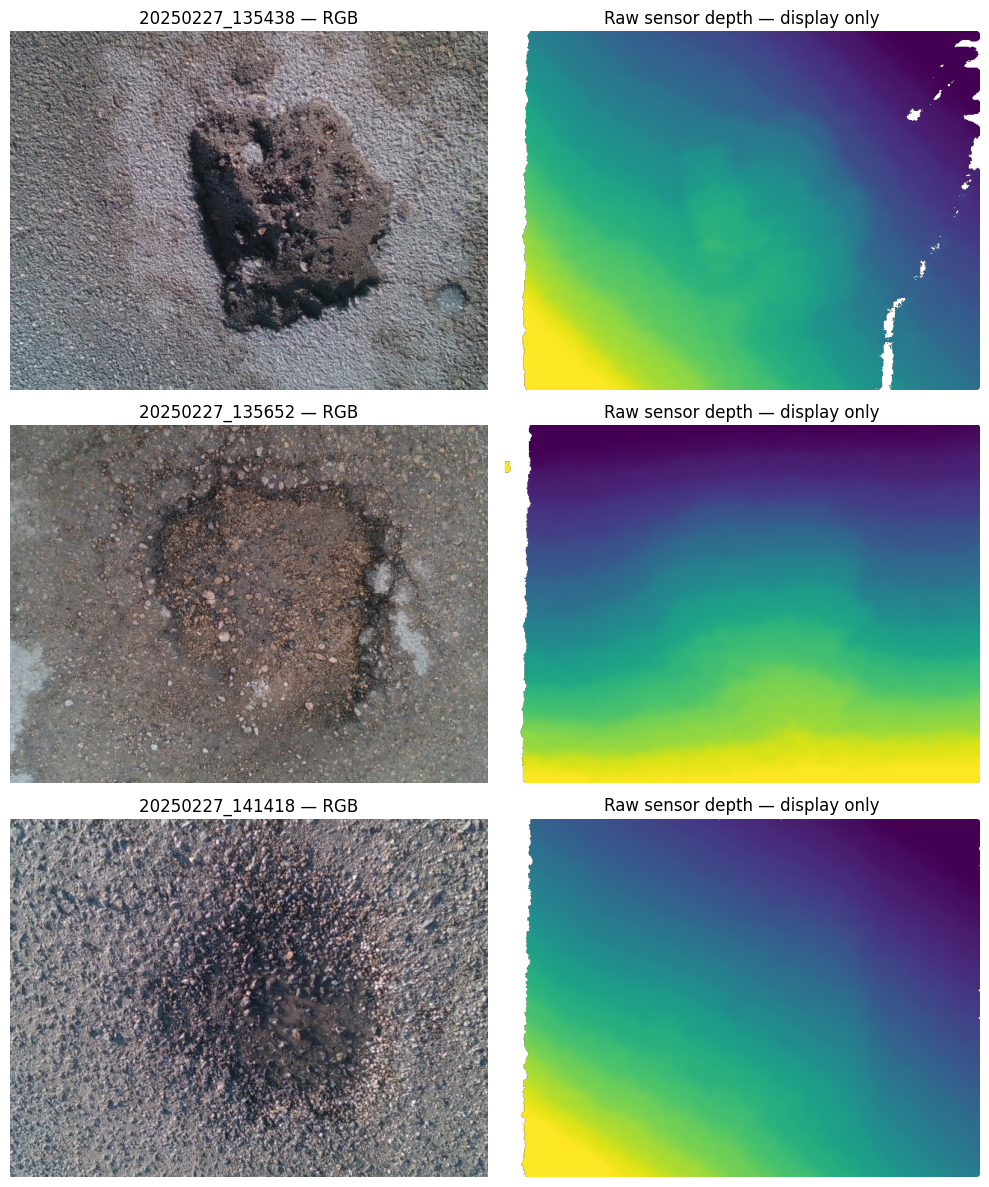


CRDL C3-09 SECTION 3B — POTHRGBD PAIRING RECOVERY
all_depth_npy_files: 1001
all_rgb_files: 1000
recognized_depth_sample_ids: 998
recognized_rgb_sample_ids: 998
unique_filename_pairs: 996
unmatched_depth_ids: 0
ambiguous_depth_ids: 2
rgb_ids_without_depth: 0
paired_with_existing_label: 996
sampled_count: 12
sample_shape_matches: 12
sample_depth_dtypes: {'uint16': 12}
historical_hash_mismatches: []

FIRST FIVE VERIFIED NAME PAIRS
20250227_135438 | 20250227_135438_depth.npy | 20250227_135438_color_png.rf.984e9768eb679052fd79e702413a94c5.jpg
20250227_135652 | 20250227_135652_depth.npy | 20250227_135652_color_png.rf.c3e37f97ea7f729ce0c04d4272dbab7d.jpg
20250227_140407 | 20250227_140407_depth.npy | 20250227_140407_color_png.rf.c4475270462eea5151c53046692d9239.jpg
20250227_140905 | 20250227_140905_depth.npy | 20250227_140905_color_png.rf.2d12799a85d2760abf8ee447509e62de.jpg
20250227_141050 | 20250227_141050_depth.npy | 20250227_141050_color_png.rf.4682f3a780dcc539b18b35c4c819567f.jpg

HISTOR

In [6]:
# =============================================================
# CRDL COMPONENT 3
# C3-09 | SECTION 3B
# POTHRGBD RGB-DEPTH PAIRING RECOVERY
#
# READ ONLY | CPU | NO TRAINING
# NO PHYSICAL UNIT ASSUMPTIONS
# =============================================================

from pathlib import Path
from collections import defaultdict, Counter
from datetime import datetime, timezone
from PIL import Image

import csv
import json
import re
import uuid
import hashlib

import numpy as np
import matplotlib.pyplot as plt


# =============================================================
# 1. VERIFY ENVIRONMENT
# =============================================================

assert all(
    k in globals()
    for k in ('RAW', 'PROJECT', 'OUT')
), "Run C3-09 Section 0 first."

DATA = (
    Path(RAW) /
    'pothrgbd' /
    'PData-main'
)

RGB_DIR = DATA / 'images'
DEPTH_DIR = DATA / 'depths'
LABEL_DIR = DATA / 'labels'

assert RGB_DIR.is_dir()
assert DEPTH_DIR.is_dir()
assert Path(OUT).is_dir()


# =============================================================
# 2. CREATE SEPARATE CORRECTED AUDIT FOLDER
# =============================================================

SEC3 = Path(OUT) / (

    'section3b_pothrgbd_pairing_fix_'

    + datetime.now(
        timezone.utc
    ).strftime('%Y%m%dT%H%M%SZ_')

    + uuid.uuid4().hex[:6]
)

SEC3.mkdir(
    parents=True,
    exist_ok=False
)

print("=" * 68)
print("CRDL C3-09 SECTION 3B — POTHRGBD PAIRING RECOVERY")
print("=" * 68)

print("RGB:", RGB_DIR)
print("DEPTH:", DEPTH_DIR)
print("LABELS:", LABEL_DIR)
print("NEW OUTPUT:", SEC3)


# =============================================================
# 3. HELPER FUNCTIONS
# =============================================================

def sha256(path):

    h = hashlib.sha256()

    with open(path, 'rb') as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(chunk)

    return h.hexdigest()


def save_json(name, value):

    (SEC3 / name).write_text(

        json.dumps(
            value,
            indent=2,
            default=str
        ),

        encoding='utf-8'
    )


def save_csv(name, rows, fields):

    with (
        SEC3 / name
    ).open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=fields
        )

        writer.writeheader()
        writer.writerows(rows)


# =============================================================
# 4. DEFINE VERIFIED FILENAME STRUCTURES
# =============================================================

# Actual dataset example:
#
# Depth:
# 20250227_135438_depth.npy
#
# RGB:
# 20250227_135438_color_png.rf.HASH.jpg
#
# Label:
# 20250227_135438_color_png.rf.HASH.txt
#
# We match by the exact capture timestamp.
# No approximate timestamp pairing.

DEPTH_RE = re.compile(

    r'^(\d{8}_\d{6})_depth$',

    re.IGNORECASE
)

RGB_RE = re.compile(

    r'^(\d{8}_\d{6})_color_png\.rf\.'
    r'([A-Za-z0-9]+)$',

    re.IGNORECASE
)


# =============================================================
# 5. DISCOVER ACTUAL SOURCE FILES
# =============================================================

depth_files = sorted(

    path

    for path in DEPTH_DIR.iterdir()

    if path.is_file()

    and not path.is_symlink()

    and path.suffix.lower() == '.npy'
)

rgb_files = sorted(

    path

    for path in RGB_DIR.iterdir()

    if path.is_file()

    and not path.is_symlink()

    and path.suffix.lower() in {

        '.jpg',
        '.jpeg',
        '.png',
        '.bmp',
        '.tif',
        '.tiff'
    }
)

print("\nSOURCE FILE COUNTS")

print("Depth arrays:", len(depth_files))
print("RGB images:", len(rgb_files))


# =============================================================
# 6. EXTRACT SAMPLE IDs
# =============================================================

def index_files(files, pattern):

    index = defaultdict(list)

    unrecognized = []

    for path in files:

        match = pattern.fullmatch(
            path.stem
        )

        if match:

            sample_id = match.group(1)

            index[sample_id].append(
                path
            )

        else:

            unrecognized.append(
                path.name
            )

    return index, unrecognized


depth_index, unknown_depth = index_files(

    depth_files,
    DEPTH_RE
)

rgb_index, unknown_rgb = index_files(

    rgb_files,
    RGB_RE
)

print("\nRECOGNIZED SAMPLE IDs")

print("Depth IDs:", len(depth_index))
print("RGB IDs:", len(rgb_index))

print("Unrecognized depth filenames:", len(unknown_depth))
print("Unrecognized RGB filenames:", len(unknown_rgb))


# =============================================================
# 7. GENERATE STRICT PAIRING MANIFEST
# =============================================================

manifest = []

unique_pairs = []

for sample_id in sorted(depth_index):

    depth_matches = depth_index[
        sample_id
    ]

    rgb_matches = rgb_index.get(
        sample_id,
        []
    )

    # -----------------------------------------
    # Status
    # -----------------------------------------

    if (
        len(depth_matches) == 1
        and len(rgb_matches) == 1
    ):

        status = 'UNIQUE_NAME_MATCH'

    elif (
        len(depth_matches) > 1
        or len(rgb_matches) > 1
    ):

        status = 'AMBIGUOUS_DUPLICATE'

    else:

        status = 'RGB_NOT_FOUND'

    # -----------------------------------------
    # Exact paths
    # -----------------------------------------

    depth_path = (

        depth_matches[0]

        if len(depth_matches) == 1

        else None
    )

    rgb_path = (

        rgb_matches[0]

        if len(rgb_matches) == 1

        else None
    )

    # -----------------------------------------
    # Corresponding segmentation label
    # -----------------------------------------

    label_path = (

        LABEL_DIR /
        (rgb_path.stem + '.txt')

        if rgb_path is not None

        else None
    )

    label_exists = bool(

        label_path is not None

        and label_path.is_file()

        and not label_path.is_symlink()
    )

    row = {

        'sample_id':
            sample_id,

        'pair_status':
            status,

        'depth_count':
            len(depth_matches),

        'rgb_count':
            len(rgb_matches),

        'depth_filename':
            depth_path.name
            if depth_path else '',

        'rgb_filename':
            rgb_path.name
            if rgb_path else '',

        'label_filename':
            label_path.name
            if label_exists else '',

        'label_exists':
            label_exists,

        'capture_day_proxy':
            sample_id[:8],

        'physical_units_verified':
            False,

        'registration_verified':
            False
    }

    manifest.append(row)

    if status == 'UNIQUE_NAME_MATCH':

        unique_pairs.append((

            sample_id,

            depth_path,

            rgb_path,

            label_path if label_exists else None
        ))


# =============================================================
# 8. SAVE FULL PAIRING MANIFEST
# =============================================================

manifest_columns = [

    'sample_id',
    'pair_status',

    'depth_count',
    'rgb_count',

    'depth_filename',
    'rgb_filename',

    'label_filename',
    'label_exists',

    'capture_day_proxy',

    'physical_units_verified',
    'registration_verified'
]

save_csv(

    'pairing_manifest_all_depths.csv',

    manifest,

    manifest_columns
)


# =============================================================
# 9. LOAD EARLIER RESEARCH EVIDENCE
# =============================================================

history = {}

historical_paths = [

    (
        Path(PROJECT) /
        '07_evaluation' /
        'C3-02_section10_PothRGBD_'
        '20261020T074328_485180Z' /
        'pothrgbd_readiness.json'
    ),

    (
        Path(PROJECT) /
        '02_dataset_audits' /
        'C3-08_section05_POTHRGBD_SCALE_EVIDENCE_'
        '20261020T180134_614755Z' /
        'source_evidence.json'
    )
]

historical_loaded = []

for path in historical_paths:

    if not path.is_file():
        continue

    document = json.loads(

        path.read_text(
            encoding='utf-8'
        )
    )

    historical_loaded.append(
        str(path)
    )

    for record in document.get(
        'records',
        []
    ):

        sample_id = record.get(
            'sample_id'
        )

        if not sample_id:
            continue

        entry = history.setdefault(
            sample_id,
            {}
        )

        historical_keys = [

            (
                'depth_sha256',
                'depth_sha256'
            ),

            (
                'depth_sha256',
                'depth_source_sha256'
            ),

            (
                'rgb_sha256',
                'rgb_sha256'
            ),

            (
                'label_sha256',
                'label_sha256'
            )
        ]

        for final_key, original_key in historical_keys:

            value = record.get(
                original_key
            )

            if not value:
                continue

            if (
                final_key in entry

                and entry[final_key] != value
            ):

                raise AssertionError(

                    'Historical audit hash conflict: '
                    + sample_id
                    + ' '
                    + final_key
                )

            entry[final_key] = value


print("\nHISTORICAL AUDIT EVIDENCE")

print(
    "Previous reports loaded:",
    len(historical_loaded)
)

print(
    "Historical sample identities:",
    len(history)
)


# =============================================================
# 10. SELECT REPRODUCIBLE QA SAMPLES
# =============================================================

unique_by_id = {

    row[0]: row

    for row in unique_pairs
}

# Prefer previously audited examples.
selected_ids = [

    sample_id

    for sample_id in sorted(history)

    if sample_id in unique_by_id

][:6]


# Add evenly spaced examples from available pairs.
if unique_pairs:

    indices = np.linspace(

        0,

        len(unique_pairs) - 1,

        num=min(
            8,
            len(unique_pairs)
        ),

        dtype=int
    )

    for index in indices:

        selected_ids.append(

            unique_pairs[
                int(index)
            ][0]
        )


# Remove repeated sample IDs.
selected_ids = list(

    dict.fromkeys(
        selected_ids
    )

)[:12]


# =============================================================
# 11. VERIFY RAW DEPTH AND RGB CONTENT
# =============================================================

samples = []

for sample_id in selected_ids:

    _, depth_path, rgb_path, label_path = (
        unique_by_id[sample_id]
    )

    record = {

        'sample_id':
            sample_id,

        'rgb_filename':
            rgb_path.name,

        'depth_filename':
            depth_path.name,

        'label_filename':
            label_path.name
            if label_path else None,

        'depth_units':
            'UNVERIFIED_RAW_SENSOR_UNITS',

        'metric_training_approved':
            False
    }

    try:

        # -----------------------------------------
        # Load original depth without conversion
        # -----------------------------------------

        depth = np.load(

            depth_path,

            mmap_mode='r',

            allow_pickle=False
        )

        record['depth_shape'] = list(
            depth.shape
        )

        record['depth_dtype'] = str(
            depth.dtype
        )

        record['depth_is_2d'] = bool(
            depth.ndim == 2
        )

        # -----------------------------------------
        # Read RGB dimensions
        # -----------------------------------------

        with Image.open(
            rgb_path
        ) as image:

            record['rgb_shape_hw'] = [

                image.height,

                image.width
            ]

            record['rgb_mode'] = (
                image.mode
            )

        # -----------------------------------------
        # Verify dimensional compatibility
        # -----------------------------------------

        record['same_pixel_dimensions'] = bool(

            depth.ndim == 2

            and list(depth.shape)
            == record['rgb_shape_hw']
        )

        # -----------------------------------------
        # Inspect valid depth statistics
        # -----------------------------------------

        if (
            depth.ndim == 2

            and np.issubdtype(
                depth.dtype,
                np.number
            )
        ):

            valid = (

                np.isfinite(depth)

                & (depth > 0)
            )

            record[
                'positive_finite_fraction'
            ] = float(
                valid.mean()
            )

            values = np.asarray(
                depth
            )[valid]

            if values.size:

                record[
                    'raw_positive_p05'
                ] = float(
                    np.percentile(
                        values,
                        5
                    )
                )

                record[
                    'raw_positive_p50'
                ] = float(
                    np.percentile(
                        values,
                        50
                    )
                )

                record[
                    'raw_positive_p95'
                ] = float(
                    np.percentile(
                        values,
                        95
                    )
                )

        # -----------------------------------------
        # Cryptographic source identity
        # -----------------------------------------

        record['depth_sha256'] = sha256(
            depth_path
        )

        record['rgb_sha256'] = sha256(
            rgb_path
        )

        if label_path:

            record['label_sha256'] = sha256(
                label_path
            )

        # -----------------------------------------
        # Compare with our earlier audits
        # -----------------------------------------

        expected_hashes = history.get(
            sample_id,
            {}
        )

        record['historical_hash_checks'] = {

            key: (

                'MATCH'

                if record.get(key) == value

                else 'MISMATCH'
            )

            for key, value
            in expected_hashes.items()

            if key in {

                'depth_sha256',
                'rgb_sha256',
                'label_sha256'
            }
        }

    except Exception as error:

        record['inspection_error'] = (

            type(error).__name__

            + ': '

            + str(error)[:180]
        )

    samples.append(
        record
    )


# =============================================================
# 12. CREATE RGB / RAW DEPTH VISUAL QA FIGURE
# =============================================================

# Visualization only.
# The depth map is stretched for display.
# No physical conversion occurs.

if selected_ids:

    nshow = min(
        3,
        len(selected_ids)
    )

    fig, axes = plt.subplots(

        nshow,
        2,

        figsize=(
            10,
            4 * nshow
        ),

        squeeze=False
    )

    for row_index, sample_id in enumerate(
        selected_ids[:nshow]
    ):

        _, depth_path, rgb_path, _ = (
            unique_by_id[sample_id]
        )

        with Image.open(
            rgb_path
        ) as image:

            rgb = np.asarray(
                image.convert('RGB')
            )

        depth = np.load(

            depth_path,

            mmap_mode='r',

            allow_pickle=False
        )

        axes[row_index, 0].imshow(
            rgb
        )

        axes[row_index, 0].set_title(
            sample_id + ' — RGB'
        )

        if depth.ndim == 2:

            valid = (

                np.isfinite(depth)

                & (depth > 0)
            )

            values = np.asarray(
                depth
            )[valid]

            if values.size:

                lo, hi = np.percentile(
                    values,
                    [2, 98]
                )

                hi = max(
                    hi,
                    lo + 1
                )

                display_depth = np.ma.masked_where(

                    ~valid,

                    depth
                )

                axes[row_index, 1].imshow(

                    display_depth,

                    cmap='viridis',

                    vmin=lo,
                    vmax=hi
                )

        axes[row_index, 1].set_title(

            'Raw sensor depth — display only'
        )

        for ax in axes[row_index]:

            ax.axis('off')

    plt.tight_layout()

    plt.savefig(

        SEC3 /
        'rgb_raw_depth_contact_sheet.png',

        dpi=150,

        bbox_inches='tight'
    )

    plt.show()

    plt.close(fig)


# =============================================================
# 13. CHECK HISTORICAL HASH MISMATCHES
# =============================================================

hash_mismatches = [

    (
        record['sample_id'],
        key
    )

    for record in samples

    for key, status
    in record.get(
        'historical_hash_checks',
        {}
    ).items()

    if status == 'MISMATCH'
]


# =============================================================
# 14. BUILD CONSERVATIVE SUMMARY
# =============================================================

summary = {

    'stage':
        'C3-09_SECTION3B_PAIRING_RECOVERY',

    'all_depth_npy_files':
        len(depth_files),

    'all_rgb_files':
        len(rgb_files),

    'recognized_depth_sample_ids':
        len(depth_index),

    'recognized_rgb_sample_ids':
        len(rgb_index),

    'unique_filename_pairs':
        len(unique_pairs),

    'unmatched_depth_ids':

        sum(

            row['pair_status']
            == 'RGB_NOT_FOUND'

            for row in manifest
        ),

    'ambiguous_depth_ids':

        sum(

            row['pair_status']
            == 'AMBIGUOUS_DUPLICATE'

            for row in manifest
        ),

    'rgb_ids_without_depth':
        len(
            set(rgb_index)
            - set(depth_index)
        ),

    'unrecognized_depth_filenames':
        unknown_depth[:20],

    'unrecognized_rgb_filenames':
        unknown_rgb[:20],

    'paired_with_existing_label':

        sum(

            row['label_exists']

            for row in manifest

            if row['pair_status']
            == 'UNIQUE_NAME_MATCH'
        ),

    'historical_reports_loaded':
        historical_loaded,

    'sampled_count':
        len(samples),

    'historical_hash_mismatches':
        hash_mismatches,

    'sample_shape_matches':

        sum(

            record.get(
                'same_pixel_dimensions',
                False
            )

            for record in samples
        ),

    'sample_depth_dtypes':
        dict(
            Counter(

                record.get(
                    'depth_dtype',
                    'ERROR'
                )

                for record in samples
            )
        ),

    'physical_units_verified':
        False,

    'pixel_registration_verified':
        False,

    'metric_training_authorized':
        False,

    'independent_scene_groups_verified':
        False,

    'note':
        'Matching filenames and dimensions do '
        'not establish physical units, true '
        'RGB-depth registration or independent '
        'scene grouping.'
}


# =============================================================
# 15. SAVE COMPLETE EVIDENCE
# =============================================================

save_json(

    'pairing_recovery_summary.json',

    summary
)

save_json(

    'sampled_pair_integrity_and_raw_depth.json',

    samples
)

sample_columns = sorted({

    key

    for record in samples

    for key in record
})

save_csv(

    'sampled_pair_integrity_and_raw_depth.csv',

    samples,

    sample_columns
    if sample_columns
    else ['sample_id']
)


# =============================================================
# 16. PRINT FINAL DIAGNOSTICS
# =============================================================

print("\n" + "=" * 70)

print(
    "CRDL C3-09 SECTION 3B — POTHRGBD PAIRING RECOVERY"
)

print("=" * 70)

for key in [

    'all_depth_npy_files',

    'all_rgb_files',

    'recognized_depth_sample_ids',

    'recognized_rgb_sample_ids',

    'unique_filename_pairs',

    'unmatched_depth_ids',

    'ambiguous_depth_ids',

    'rgb_ids_without_depth',

    'paired_with_existing_label',

    'sampled_count',

    'sample_shape_matches',

    'sample_depth_dtypes',

    'historical_hash_mismatches'
]:

    print(
        key + ':',
        summary[key]
    )


print("\nFIRST FIVE VERIFIED NAME PAIRS")

first_five = [

    row

    for row in manifest

    if row['pair_status']
    == 'UNIQUE_NAME_MATCH'

][:5]

for row in first_five:

    print(

        row['sample_id'],

        '|',

        row['depth_filename'],

        '|',

        row['rgb_filename']
    )


print("\nHISTORICAL CHECKS")

for record in samples[:6]:

    print(

        record['sample_id'],

        record.get(
            'historical_hash_checks',
            {}
        )
    )


print("\nPHYSICAL UNITS VERIFIED: NO")

print("RGB-DEPTH REGISTRATION PROVEN: NO")

print("METRIC ML TRAINING AUTHORIZED: NO")

print("\nSAVED TO:")
print(SEC3)

print("=" * 70)

if hash_mismatches:

    print(
        "WARNING: Historical SHA-256 mismatches. "
        "Stop and investigate before using these "
        "pairs for model training."
    )

C3-09 SECTION 4A — POTHRGBD ROAD SIGNAL AUDIT
Matched labeled pairs: 996
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662/section4a_road_signal_qa_20261021T033852Z_e8af43


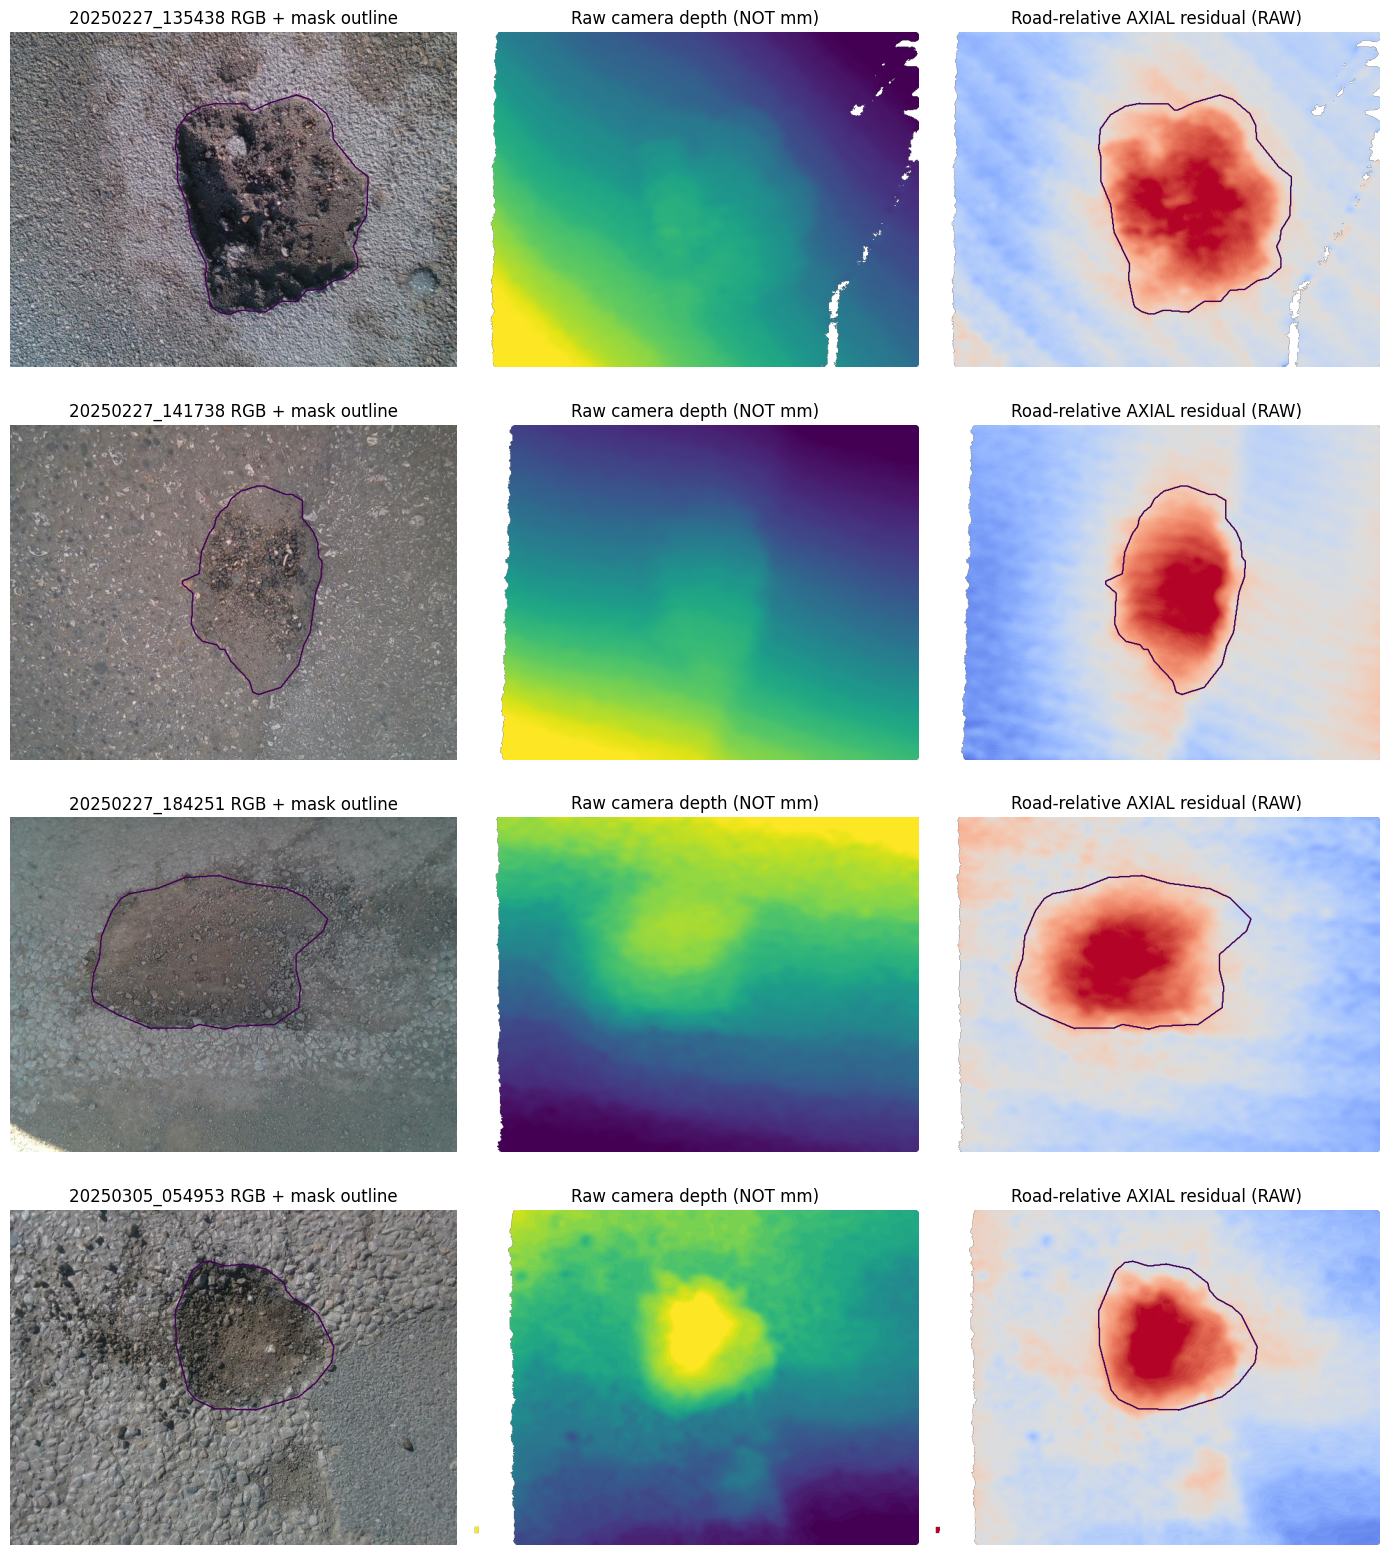


CRDL C3-09 SECTION 4A — ROAD-RELATIVE RAW DEPTH QA
Audited development examples: 14
QA outcomes: {'EXPLORATORY_PASS': 7, 'REVIEW': 7}
20250227_135438 | EXPLORATORY_PASS | ratio= 4.13 | flags= []
20250227_141738 | EXPLORATORY_PASS | ratio= 3.56 | flags= []
20250227_184251 | EXPLORATORY_PASS | ratio= 3.83 | flags= []
20250305_054953 | EXPLORATORY_PASS | ratio= 3.95 | flags= []
20250305_073146 | EXPLORATORY_PASS | ratio= 3.63 | flags= []
20250305_110414 | EXPLORATORY_PASS | ratio= 2.24 | flags= []
20250227_140905 | REVIEW | ratio= 1.05 | flags= ['WEAK_SIGNAL_VS_ROAD_NOISE', 'ROAD_REFERENCE_UNSTABLE']
20250305_052830 | REVIEW | ratio= 1.59 | flags= ['ROAD_REFERENCE_UNSTABLE']
20250305_082316 | REVIEW | ratio= 1.37 | flags= ['LOW_MASK_DEPTH_COVERAGE', 'WEAK_SIGNAL_VS_ROAD_NOISE', 'ROAD_REFERENCE_UNSTABLE']
20250227_185350 | REVIEW | ratio= 1.98 | flags= ['ROAD_REFERENCE_UNSTABLE']
20250305_053657 | REVIEW | ratio= 1.81 | flags= ['ROAD_REFERENCE_UNSTABLE']
20250305_100002 | REVIEW | ratio= 

In [7]:
# =============================================================
# CRDL COMPONENT 3 — C3-09 SECTION 4A
# POTHRGBD ROAD-RELATIVE GEOMETRY QUALITY AUDIT
#
# READ ONLY | CPU | NO TRAINING
# RAW SENSOR UNITS ONLY — NOT MILLIMETRES
# =============================================================

from pathlib import Path
from collections import Counter
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
import csv
import json
import uuid


# =============================================================
# 1. VERIFY PREVIOUS ENVIRONMENT
# =============================================================

assert (
    "SEC3" in globals()
    and Path(SEC3).is_dir()
), "Run Section 3B first."

assert (
    "DATA" in globals()
    and Path(DATA).is_dir()
)

# Create a unique new output folder.
SAVE4 = Path(OUT) / (

    "section4a_road_signal_qa_"

    + datetime.now(
        timezone.utc
    ).strftime("%Y%m%dT%H%M%SZ_")

    + uuid.uuid4().hex[:6]
)

SAVE4.mkdir(
    parents=True,
    exist_ok=False
)


# =============================================================
# 2. LOAD VERIFIED PAIRING MANIFEST
# =============================================================

with (
    Path(SEC3) /
    "pairing_manifest_all_depths.csv"
).open(newline="") as f:

    manifest = list(
        csv.DictReader(f)
    )


good = {

    r["sample_id"]: r

    for r in manifest

    if (
        r["pair_status"] == "UNIQUE_NAME_MATCH"
        and r["label_exists"] == "True"
    )
}

assert len(good) >= 10

# Path safety for filenames.
assert not any(

    "/" in r["rgb_filename"]
    or "/" in r["depth_filename"]

    for r in good.values()
)

print("=" * 70)
print("C3-09 SECTION 4A — POTHRGBD ROAD SIGNAL AUDIT")
print("=" * 70)

print("Matched labeled pairs:", len(good))
print("Output:", SAVE4)


# =============================================================
# 3. SELECT DEVELOPMENT-ONLY AUDIT SAMPLES
# =============================================================

# Include examples from previous quality investigations.
# These are NOT a new random training/test split.

prior_pass = [

    "20250227_135438",
    "20250227_141738",
    "20250227_184251",

    "20250305_054953",
    "20250305_073146",
    "20250305_110414"
]

prior_fail = [

    "20250227_140905",

    "20250305_052830",
    "20250305_082316"
]


ids = [

    x for x in prior_pass + prior_fail

    if x in good
]


# Add samples across the available filename range.
all_ids = sorted(good)

for index in np.linspace(

    0,
    len(all_ids) - 1,

    6,
    dtype=int
):

    candidate = all_ids[int(index)]

    if candidate not in ids:
        ids.append(candidate)


ids = ids[:15]


# =============================================================
# 4. LOAD YOLO SEGMENTATION POLYGONS
# =============================================================

def polygon_mask(path, width, height):

    canvas = Image.new(
        "L",
        (width, height),
        0
    )

    draw = ImageDraw.Draw(canvas)

    n_poly = 0
    warnings = []
    classes = Counter()

    for lineno, line in enumerate(

        Path(path).read_text().splitlines(),
        start=1
    ):

        parts = line.strip().split()

        if not parts:
            continue

        try:

            values = np.array(

                [float(t) for t in parts],

                dtype=np.float64
            )

            class_id = int(values[0])

            classes[class_id] += 1

            # Require YOLO segmentation polygons.
            # Do not silently interpret bounding boxes.

            valid_annotation = (

                len(values) >= 7

                and (len(values) - 1) % 2 == 0

                and np.isfinite(values).all()

                and (values[1:] >= 0).all()

                and (values[1:] <= 1).all()

                and class_id == 0
            )

            if not valid_annotation:

                warnings.append(
                    f"line {lineno}: invalid polygon"
                )

                continue

            xy = values[1:].reshape(-1, 2)

            points = [

                (
                    round(float(x) * (width - 1)),
                    round(float(y) * (height - 1))
                )

                for x, y in xy
            ]

            draw.polygon(
                points,
                fill=1
            )

            n_poly += 1

        except (ValueError, IndexError):

            warnings.append(
                f"line {lineno}: parsing failure"
            )

    return (

        np.asarray(
            canvas,
            dtype=bool
        ),

        n_poly,

        dict(classes),

        warnings
    )


# =============================================================
# 5. ROBUST INVERSE-DEPTH ROAD REFERENCE
# =============================================================

# For an approximately planar road under a pinhole
# camera, inverse axial depth is approximately affine
# in image coordinates.
#
# This is an exploratory reference-fitting diagnostic.
# It is NOT calibrated 3D normal-distance measurement.

def robust_inv_plane(u, v, z, n_iter=8):

    A = np.column_stack((

        u,

        v,

        np.ones(len(u))
    ))

    target = 1.0 / z

    coef = np.linalg.lstsq(

        A,
        target,

        rcond=None

    )[0]

    # Iteratively reweighted least squares.
    for _ in range(n_iter):

        residual = target - A @ coef

        scale = (

            1.4826

            * np.median(

                np.abs(

                    residual
                    - np.median(residual)
                )
            )

            + 1e-12
        )

        weights = np.sqrt(

            np.minimum(

                1.0,

                1.345 * scale
                /
                (np.abs(residual) + 1e-12)
            )
        )

        coef = np.linalg.lstsq(

            A * weights[:, None],

            target * weights,

            rcond=None

        )[0]

    return coef


# =============================================================
# 6. INITIALIZE QA RESULTS
# =============================================================

rng = np.random.default_rng(20261021)

reports = []

plot_items = []


# =============================================================
# 7. AUDIT SELECTED RAW DEPTH SCENES
# =============================================================

for sample_id in ids:

    row = good[sample_id]

    rec = {

        "sample_id": sample_id,

        "audit_role":
            "DEVELOPMENT_DIAGNOSTIC_ONLY",

        "physical_units":
            "UNVERIFIED",

        "training_approved":
            False
    }

    try:

        depth_path = (

            Path(DATA)
            / "depths"
            / row["depth_filename"]
        )

        rgb_path = (

            Path(DATA)
            / "images"
            / row["rgb_filename"]
        )

        label_path = (

            Path(DATA)
            / "labels"
            / row["label_filename"]
        )

        assert all(

            p.is_file()
            and not p.is_symlink()

            for p in (
                depth_path,
                rgb_path,
                label_path
            )
        )

        # -----------------------------------------
        # Read original arrays
        # -----------------------------------------

        depth = np.load(

            depth_path,

            allow_pickle=False
        )

        with Image.open(rgb_path) as im:

            rgb = np.asarray(
                im.convert("RGB")
            )

        assert depth.ndim == 2

        assert depth.shape == rgb.shape[:2]

        assert np.issubdtype(
            depth.dtype,
            np.number
        )

        h, w = depth.shape

        # -----------------------------------------
        # Decode segmentation polygons
        # -----------------------------------------

        mask, n_poly, classes, warnings = (
            polygon_mask(
                label_path,
                w,
                h
            )
        )

        rec.update({

            "depth_dtype":
                str(depth.dtype),

            "polygon_count":
                n_poly,

            "class_counts":
                classes,

            "annotation_warnings":
                warnings,

            "mask_fraction":
                float(mask.mean())
        })

        if (
            warnings
            or n_poly == 0
            or mask.sum() < 100
        ):

            rec["qa_status"] = (
                "ANNOTATION_REVIEW"
            )

            reports.append(rec)
            continue

        # -----------------------------------------
        # Valid sensor pixels
        # -----------------------------------------

        valid = (

            np.isfinite(depth)

            & (depth > 0)
        )

        maskvalid = mask & valid

        # -----------------------------------------
        # Healthy road support ring
        # -----------------------------------------

        # Distance in image pixels from defect mask.
        distance = distance_transform_edt(
            ~mask
        )

        ring = (

            (distance >= 8)

            & (distance <= 55)

            & valid
        )

        rec["mask_depth_valid_fraction"] = float(

            maskvalid.sum()
            / mask.sum()
        )

        rec["road_ring_valid_pixels"] = int(
            ring.sum()
        )

        if (

            maskvalid.sum() < 100

            or ring.sum() < 2500
        ):

            rec["qa_status"] = (
                "INSUFFICIENT_VALID_SUPPORT"
            )

            reports.append(rec)
            continue

        # -----------------------------------------
        # Normalize image coordinates
        # -----------------------------------------

        y, x = np.indices(
            (h, w)
        )

        un = (
            2.0 * (x + 0.5) / w - 1.0
        )

        vn = (
            2.0 * (y + 0.5) / h - 1.0
        )

        # -----------------------------------------
        # Sample healthy-road pixels
        # -----------------------------------------

        sy, sx = np.where(ring)

        if len(sy) > 15000:

            chosen = rng.choice(

                len(sy),

                size=15000,

                replace=False
            )

            sy = sy[chosen]
            sx = sx[chosen]

        # -----------------------------------------
        # Robust healthy-road fit
        # -----------------------------------------

        coef = robust_inv_plane(

            un[sy, sx],

            vn[sy, sx],

            depth[sy, sx].astype(float)
        )

        denominator = (

            coef[0] * un

            + coef[1] * vn

            + coef[2]
        )

        good_denom = (
            denominator > 1e-9
        )

        road_reference = np.full(

            depth.shape,

            np.nan,

            dtype=np.float64
        )

        road_reference[good_denom] = (

            1.0
            /
            denominator[good_denom]
        )

        usable = valid & good_denom

        inside = mask & usable

        support = ring & usable

        if (

            inside.sum() < 100

            or support.sum() < 1000
        ):

            rec["qa_status"] = (
                "INVALID_REFERENCE"
            )

            reports.append(rec)
            continue

        # -----------------------------------------
        # Road-relative AXIAL residual
        # -----------------------------------------

        # The sign depends on the camera coordinate
        # convention. This is NOT road-normal depth.

        axial_residual = (

            depth.astype(float)

            - road_reference
        )

        signed = float(

            np.median(
                axial_residual[inside]
            )
        )

        ring_error = float(

            np.percentile(

                np.abs(
                    axial_residual[support]
                ),

                95
            )
        )

        signal = float(

            np.median(

                np.abs(
                    axial_residual[inside]
                )
            )
        )

        # -----------------------------------------
        # Spatial road-model holdout checks
        # -----------------------------------------

        cy, cx = np.mean(

            np.where(mask),

            axis=1
        )

        sector = (

            (sy >= cy).astype(int) * 2

            + (sx >= cx).astype(int)
        )

        holdout_errors = []

        for sector_id in range(4):

            train = (
                sector != sector_id
            )

            test = (
                sector == sector_id
            )

            if (

                train.sum() < 1500

                or test.sum() < 150
            ):
                continue

            b = robust_inv_plane(

                un[sy[train], sx[train]],

                vn[sy[train], sx[train]],

                depth[
                    sy[train],
                    sx[train]
                ].astype(float)
            )

            q = (

                b[0] * un[
                    sy[test],
                    sx[test]
                ]

                + b[1] * vn[
                    sy[test],
                    sx[test]
                ]

                + b[2]
            )

            usable_test = (
                q > 1e-9
            )

            if usable_test.sum() < 150:
                continue

            predicted = (
                1.0 / q[usable_test]
            )

            observed = depth[

                sy[test][usable_test],

                sx[test][usable_test]

            ].astype(float)

            holdout_errors.append(

                float(

                    np.percentile(

                        np.abs(
                            observed - predicted
                        ),

                        95
                    )
                )
            )

        worst = (

            max(holdout_errors)

            if holdout_errors

            else None
        )

        # -----------------------------------------
        # Exploratory quality flags
        # -----------------------------------------

        flags = []

        if (
            rec["mask_depth_valid_fraction"]
            < 0.9
        ):

            flags.append(
                "LOW_MASK_DEPTH_COVERAGE"
            )

        if len(holdout_errors) < 4:

            flags.append(
                "INCOMPLETE_SECTOR_HOLDOUT"
            )

        if (

            signal / (ring_error + 1e-9)

            < 1.5
        ):

            flags.append(
                "WEAK_SIGNAL_VS_ROAD_NOISE"
            )

        if (

            worst is None

            or worst / (signal + 1e-9) > 0.5
        ):

            flags.append(
                "ROAD_REFERENCE_UNSTABLE"
            )

        if signed <= 0:

            flags.append(
                "DEPRESSION_SIGN_UNCERTAIN"
            )

        rec.update({

            "qa_status":

                "EXPLORATORY_PASS"

                if not flags

                else "REVIEW",

            "flags":
                flags,

            "signed_median_axial_residual_RAW":
                signed,

            "abs_median_axial_residual_RAW":
                signal,

            "road_fit_abs_p95_RAW":
                ring_error,

            "signal_to_road_ratio":

                signal
                / (ring_error + 1e-9),

            "heldout_sector_abs_p95_RAW":
                holdout_errors,

            "worst_holdout_to_signal":

                None

                if worst is None

                else worst
                / (signal + 1e-9),

            "positive_fraction_inside":

                float(
                    np.mean(
                        axial_residual[inside] > 0
                    )
                )
        })

        # Preserve up to 4 examples for visualization.
        if len(plot_items) < 4:

            plot_items.append((

                sample_id,
                rgb,
                mask,

                depth.astype(float),

                axial_residual,

                usable
            ))

    except Exception as error:

        rec["qa_status"] = (
            "INSPECTION_ERROR"
        )

        rec["error"] = (

            type(error).__name__

            + ": "

            + str(error)[:180]
        )

    reports.append(rec)


# =============================================================
# 8. SAVE PER-IMAGE AUDIT
# =============================================================

(
    SAVE4 / "geometry_quality_audit.json"
).write_text(

    json.dumps(
        reports,
        indent=2,
        default=str
    ),

    encoding="utf-8"
)

all_keys = sorted({

    key

    for row in reports

    for key in row
})

with (
    SAVE4 / "geometry_quality_audit.csv"
).open(
    "w",
    newline=""
) as f:

    writer = csv.DictWriter(

        f,

        fieldnames=all_keys
    )

    writer.writeheader()
    writer.writerows(reports)


# =============================================================
# 9. VISUALIZE ROAD-RELATIVE RAW DEPTH
# =============================================================

if plot_items:

    fig, axes = plt.subplots(

        len(plot_items),

        3,

        figsize=(
            14,
            4 * len(plot_items)
        ),

        squeeze=False
    )

    for i, (
        sid,
        rgb,
        mask,
        raw,
        residual,
        valid
    ) in enumerate(plot_items):

        # -----------------------------------------
        # RGB + damage mask
        # -----------------------------------------

        axes[i, 0].imshow(rgb)

        axes[i, 0].contour(

            mask.astype(int),

            levels=[0.5],

            linewidths=1
        )

        axes[i, 0].set_title(
            sid + " RGB + mask outline"
        )

        # -----------------------------------------
        # Raw axial camera depth
        # -----------------------------------------

        values = raw[

            (raw > 0)

            & np.isfinite(raw)
        ]

        lo, hi = np.percentile(
            values,
            [2, 98]
        )

        hi = max(
            hi,
            lo + 1
        )

        axes[i, 1].imshow(

            np.ma.masked_where(
                raw <= 0,
                raw
            ),

            vmin=lo,
            vmax=hi,

            cmap="viridis"
        )

        axes[i, 1].set_title(
            "Raw camera depth (NOT mm)"
        )

        # -----------------------------------------
        # Road-relative axial residual
        # -----------------------------------------

        scale = float(

            np.percentile(

                np.abs(
                    residual[valid]
                ),

                98
            )
        )

        scale = max(
            scale,
            1.0
        )

        axes[i, 2].imshow(

            np.ma.masked_where(

                ~valid,

                residual
            ),

            cmap="coolwarm",

            vmin=-scale,

            vmax=scale
        )

        axes[i, 2].contour(

            mask.astype(int),

            levels=[0.5],

            linewidths=1
        )

        axes[i, 2].set_title(

            "Road-relative AXIAL residual (RAW)"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()

    plt.savefig(

        SAVE4 / "road_relative_raw_qa.png",

        dpi=140,

        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# =============================================================
# 10. CREATE SCIENTIFIC DECISION REPORT
# =============================================================

summary = {

    "stage":
        "C3-09_SECTION4A",

    "audit_samples":
        len(reports),

    "status_counts":

        dict(
            Counter(
                r["qa_status"]
                for r in reports
            )
        ),

    "source_matched_pairs":
        len(good),

    "source_ambiguous_ids":

        sum(

            r["pair_status"]
            == "AMBIGUOUS_DUPLICATE"

            for r in manifest
        ),

    "metric_depth_approved":
        False,

    "camera_intrinsics_verified":
        False,

    "rgb_depth_registration_proven":
        False,

    "physical_measurement_validation":
        False,

    "interpretation":

        "Pixel-space inverse-depth road-plane "
        "diagnostics only. Raw residuals are not "
        "millimetres. Diagnostic PASS does not "
        "authorize metric training."
}


(
    SAVE4 / "section4a_decision.json"
).write_text(

    json.dumps(
        summary,
        indent=2
    ),

    encoding="utf-8"
)


# =============================================================
# 11. PRINT FINAL RESULTS
# =============================================================

print("\n" + "=" * 70)

print(
    "CRDL C3-09 SECTION 4A — ROAD-RELATIVE RAW DEPTH QA"
)

print("=" * 70)

print(
    "Audited development examples:",
    len(reports)
)

print(
    "QA outcomes:",
    summary["status_counts"]
)

for r in reports:

    print(

        r["sample_id"],

        "|", r["qa_status"],

        "| ratio=",

        round(

            r.get(
                "signal_to_road_ratio",
                float("nan")
            ),

            2
        ),

        "| flags=",

        r.get(
            "flags",
            []
        )
    )

print("\nVerified physical units: NO")

print("Model training performed: NO")

print("\nSaved:")
print(SAVE4)

print(
    "\nNEXT: Source-specific calibration, "
    "intrinsics, registration and Fan XYZ."
)

print("=" * 70)

In [8]:
# =============================================================
# CRDL COMPONENT 3
# C3-09 SECTION 4B
#
# POTHRGBD CALIBRATION EVIDENCE
# AND ACQUISITION-GROUP AUDIT
#
# READ ONLY | CPU | NO TRAINING
#
# PURPOSE:
# 1. Preserve 996 matched RGB-depth-label pairs.
# 2. Recover local sensor calibration metadata.
# 3. Build provisional acquisition-time groups.
# 4. Examine depth-scale sensitivity.
# 5. Record scientific GO/NO-GO evidence.
#
# No protected evaluation data accessed.
# No previous experiment overwritten.
# =============================================================

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone

import os
import csv
import json
import re
import uuid
import hashlib

import numpy as np


# =============================================================
# 1. VERIFY PREVIOUS SECTIONS
# =============================================================

assert all(
    k in globals()
    for k in (
        'OUT',
        'SEC3',
        'DATA',
        'SAVE4'
    )
), (
    "Run Sections 3B and 4A "
    "in the same Colab runtime."
)

for folder in (
    OUT,
    SEC3,
    DATA,
    SAVE4
):

    assert Path(folder).is_dir(), (
        f'Missing prerequisite folder: {folder}'
    )


# =============================================================
# 2. CREATE A VERSIONED OUTPUT FOLDER
# =============================================================

C4B = Path(OUT) / (

    'section4b_scale_group_evidence_'

    + datetime.now(
        timezone.utc
    ).strftime('%Y%m%dT%H%M%SZ_')

    + uuid.uuid4().hex[:6]
)

C4B.mkdir(
    parents=True,
    exist_ok=False
)


def dump_json(name, obj):

    (C4B / name).write_text(

        json.dumps(
            obj,
            indent=2,
            default=str
        ),

        encoding='utf-8'
    )


def dump_csv(name, rows, columns):

    with (
        C4B / name
    ).open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=columns
        )

        writer.writeheader()
        writer.writerows(rows)


# =============================================================
# 3. READ THE RECOVERED PAIRING MANIFEST
# =============================================================

pairing_file = (

    Path(SEC3) /
    'pairing_manifest_all_depths.csv'
)

with pairing_file.open(
    newline='',
    encoding='utf-8'
) as f:

    pairs = list(
        csv.DictReader(f)
    )

assert pairs, (
    'Pairing manifest is empty.'
)

unique = [

    row

    for row in pairs

    if (

        row['pair_status']
        == 'UNIQUE_NAME_MATCH'

        and str(
            row['label_exists']
        ).lower() == 'true'
    )
]

assert len(unique) >= 100, (
    'Unexpectedly few matched labeled pairs.'
)


# =============================================================
# 4. LOAD PREVIOUS ROAD-SIGNAL QA EVIDENCE
# =============================================================

qa_file = (

    Path(SAVE4) /
    'geometry_quality_audit.json'
)

with qa_file.open(
    encoding='utf-8'
) as f:

    qa = json.load(f)


# =============================================================
# 5. BUILD TEMPORAL CAPTURE-GROUP PROXIES
# =============================================================

# Filename timestamps can identify close captures.
#
# IMPORTANT:
# These are provisional grouping candidates.
# They do NOT prove independent physical scenes.
#
# No training/test split is created here.

stamps = []

for row in unique:

    sample_id = row['sample_id']

    try:

        capture_time = datetime.strptime(

            sample_id,

            '%Y%m%d_%H%M%S'
        )

    except ValueError:

        continue

    stamps.append((
        capture_time,
        row
    ))


stamps.sort(
    key=lambda item: item[0]
)

temporal = []

previous_time = None

burst_id = -1

for capture_time, row in stamps:

    new_burst = (

        previous_time is None

        or capture_time.date()
        != previous_time.date()

        or (
            capture_time - previous_time
        ).total_seconds() > 30 * 60
    )

    if new_burst:

        burst_id += 1

    temporal.append({

        'sample_id':
            row['sample_id'],

        'capture_date_proxy':
            capture_time.date().isoformat(),

        'half_hour_burst_proxy':
            f'POTHRGBD_TEMPORAL_{burst_id:04d}',

        'rgb_filename':
            row['rgb_filename'],

        'depth_filename':
            row['depth_filename'],

        'capture_group_verified':
            False,

        'official_split_verified':
            False,

        'safe_to_use_as_independent_test':
            False
    })

    previous_time = capture_time


# =============================================================
# 6. SAVE GROUPING PROXIES
# =============================================================

dump_csv(

    'temporal_groups_PROXIES_NOT_SPLITS.csv',

    temporal,

    list(temporal[0])
)


# =============================================================
# 7. SCAN LOCAL SENSOR METADATA
# =============================================================

# Only inspect the explicit PothRGBD dataset root.
# Do not scan protected neighbouring datasets.

BANNED = {

    'test',
    'testing',

    'val',
    'validation',

    'holdout',
    'heldout',

    'dataset2',
    'reserved',

    'phase13',
    'frozen399'
}


def norm(text):

    return re.sub(

        r'[\s_-]+',

        '',

        text.lower()
    )


DOC_EXT = {

    '.md',
    '.txt',

    '.json',

    '.yaml',
    '.yml',

    '.toml',
    '.ini',
    '.cfg',

    '.py',
    '.xml'
}


# Search for references to the original
# sensor's calibration and depth encoding.

KEYWORDS = (

    'depth_scale',

    'get_depth_scale',

    'get_units',

    'depth_units',

    'intrinsic',

    'extrinsic',

    'rs.align',

    'aligned_depth',

    'align_to',

    'calibration',

    'd415',

    'millimeter',
    'millimetre',

    'focal_length',

    'fx:',
    'fy:'
)


found = []

visited = 0

truncated = False


for folder, dirs, filenames in os.walk(

    DATA,

    followlinks=False
):

    folder = Path(folder)

    dirs[:] = sorted(

        d

        for d in dirs

        if (

            norm(d) not in BANNED

            and not (
                folder / d
            ).is_symlink()
        )
    )

    for filename in sorted(filenames):

        path = folder / filename

        if path.is_symlink():

            continue

        visited += 1

        if visited > 6500:

            truncated = True
            break

        if path.suffix.lower() not in DOC_EXT:

            continue

        if path.stat().st_size > 500_000:

            continue

        if any(

            norm(part) in BANNED

            for part in path.relative_to(
                DATA
            ).parts

        ):

            continue

        try:

            lines = path.read_text(

                encoding='utf-8',

                errors='replace'
            ).splitlines()

        except OSError:

            continue

        matching_lines = [

            {

                'line': i,

                'text': line[:220]
            }

            for i, line in enumerate(
                lines,
                start=1
            )

            if any(

                keyword in line.lower()

                for keyword in KEYWORDS
            )

        ][:12]

        interesting_name = any(

            keyword in filename.lower()

            for keyword in (

                'calib',
                'readme',
                'camera',
                'depth',
                'intrin'
            )
        )

        if matching_lines or interesting_name:

            h = hashlib.sha256(

                path.read_bytes()
            ).hexdigest()

            found.append({

                'path':
                    str(path),

                'sha256':
                    h,

                'hits':
                    matching_lines
            })

    if truncated:

        break


dump_json(

    'local_calibration_metadata_candidates.json',

    found
)


# =============================================================
# 8. HYPOTHETICAL DEPTH-SCALE SENSITIVITY
# =============================================================

# These are controlled sensitivity scenarios.
#
# They are NOT validated camera settings.
# Results are illustrative axial offsets,
# NOT physically validated pothole depths.

SCALE_SCENARIOS = [

    0.0005,

    0.001,

    0.002
]

scenarios = []

for row in qa:

    raw_value = row.get(

        'signed_median_axial_residual_RAW'
    )

    if raw_value is None:

        continue

    for scale in SCALE_SCENARIOS:

        illustrative_mm = (

            float(raw_value)

            * scale

            * 1000.0
        )

        scenarios.append({

            'sample_id':
                row['sample_id'],

            'qa_status':
                row.get('qa_status'),

            'signed_axial_residual_RAW':
                float(raw_value),

            'HYPOTHETICAL_m_per_raw_unit':
                scale,

            'ILLUSTRATIVE_axial_offset_mm_NOT_VALIDATED':
                illustrative_mm,

            'road_normal_depth_validated':
                False,

            'scale_is_recording_verified':
                False
        })


dump_csv(

    'HYPOTHETICAL_scale_sensitivity_NOT_measurements.csv',

    scenarios,

    [

        'sample_id',

        'qa_status',

        'signed_axial_residual_RAW',

        'HYPOTHETICAL_m_per_raw_unit',

        'ILLUSTRATIVE_axial_offset_mm_NOT_VALIDATED',

        'road_normal_depth_validated',

        'scale_is_recording_verified'
    ]
)


# =============================================================
# 9. SUMMARIZE EXISTING GEOMETRY QUALITY
# =============================================================

status_counts = dict(

    Counter(

        row.get(
            'qa_status',
            'UNKNOWN'
        )

        for row in qa
    )
)


# =============================================================
# 10. CREATE PHYSICAL EVIDENCE GATE
# =============================================================

source_evidence = {

    'stage':
        'C3-09_SECTION4B',

    'dataset':
        'PothRGBD',

    'known_source_sensor':
        'Intel RealSense D415 '
        '(reported by dataset authors)',

    'author_reference':
        'https://arxiv.org/abs/2505.04207',

    'raw_depth_dtype_sample':
        'uint16, verified in earlier '
        'C3-09 Section 3B samples',

    'manufacturer_sdk_rule':
        'Meters = raw_value * '
        'captured_frame_depth_units_m_per_raw',

    'manufacturer_reference':
        'https://github.com/realsenseai/'
        'librealsense/wiki/'
        'Projection-in-RealSense-SDK-2.0',

    'third_party_report_mm':
        'https://arxiv.org/abs/2608.27633',

    'third_party_claim_is_capture_metadata':
        False,

    'actual_capture_depth_units_verified':
        False,

    'intrinsics_verified':
        False,

    'depth_to_color_registration_verified':
        False,

    'metric_road_normal_label_verified':
        False,

    'verified_independent_capture_groups':
        False,

    'verified_physical_measurement_reference':
        False,

    'training_on_verified_metric_labels_authorized':
        False,

    'matched_triplets':
        len(unique),

    'temporal_proxy_count':
        len(set(

            row['half_hour_burst_proxy']

            for row in temporal
        )),

    'temporal_day_count':
        len(set(

            row['capture_date_proxy']

            for row in temporal
        )),

    'excluded_ambiguous_ids':

        sum(

            row['pair_status']
            == 'AMBIGUOUS_DUPLICATE'

            for row in pairs
        ),

    'audited_quality_count':
        len(qa),

    'audited_quality_status_counts':
        status_counts,

    'source_metadata_document_count':
        len(found),

    'source_name_count_visited':
        min(visited, 6500),

    'metadata_search_truncated':
        truncated,

    'note':
        'Research evidence and temporal grouping '
        'proxies only. No metric calibration '
        'certificate or independent scene '
        'split has been established.'
}


dump_json(

    'physical_evidence_gate_v4b.json',

    source_evidence
)


# =============================================================
# 11. PRINT FINAL REPORT
# =============================================================

print("\n" + "=" * 70)

print(
    "C3-09 SECTION 4B — "
    "CALIBRATION PROVENANCE AND GROUPING"
)

print("=" * 70)

print(

    "Unique labelled RGB-depth pairs:",

    len(unique)
)

print(

    "Provisional capture days:",

    source_evidence['temporal_day_count']
)

print(

    "Provisional <=30min temporal groups:",

    source_evidence['temporal_proxy_count']
)

print(

    "Ambiguous IDs excluded:",

    source_evidence['excluded_ambiguous_ids']
)

print(

    "Previously audited QA outcomes:",

    status_counts
)

print(

    "Metadata candidates:",

    len(found),

    "search truncated:",

    truncated
)

print("\nCALIBRATION METADATA CANDIDATES:")

for record in found[:8]:

    print(

        record['path'],

        "| keyword hits:",

        len(record['hits'])
    )

print(

    "\nHypothetical conversion records:",

    len(scenarios)
)

print("\nRealSense capture depth_units verified: NO")

print("Intrinsics or alignment verified: NO")

print(
    "Independent groups or physical depth "
    "ground truth verified: NO"
)

print(
    "Physically metric CRDL training authorized: NO"
)

print("\nSaved:", C4B)

print(
    "\nNEXT: inspect candidate metadata, "
    "then Fan XYZ and source calibration evidence."
)

print("=" * 70)


C3-09 SECTION 4B — CALIBRATION PROVENANCE AND GROUPING
Unique labelled RGB-depth pairs: 996
Provisional capture days: 2
Provisional <=30min temporal groups: 5
Ambiguous IDs excluded: 2
Previously audited QA outcomes: {'EXPLORATORY_PASS': 7, 'REVIEW': 7}
Metadata candidates: 0 search truncated: False

CALIBRATION METADATA CANDIDATES:

Hypothetical conversion records: 42

RealSense capture depth_units verified: NO
Intrinsics or alignment verified: NO
Independent groups or physical depth ground truth verified: NO
Physically metric CRDL training authorized: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662/section4b_scale_group_evidence_20261021T034651Z_aade1b

NEXT: inspect candidate metadata, then Fan XYZ and source calibration evidence.


dataset1: 22 XYZ files, frames ['01', '02', '03'] ... ['20', '21', '22']
dataset3: 5 XYZ files, frames ['01', '02', '03'] ... ['03', '04', '05']

Frame records inventoried: 27
QA frames selected: [('dataset1', '01'), ('dataset1', '12'), ('dataset1', '22'), ('dataset3', '01'), ('dataset3', '03'), ('dataset3', '05')]


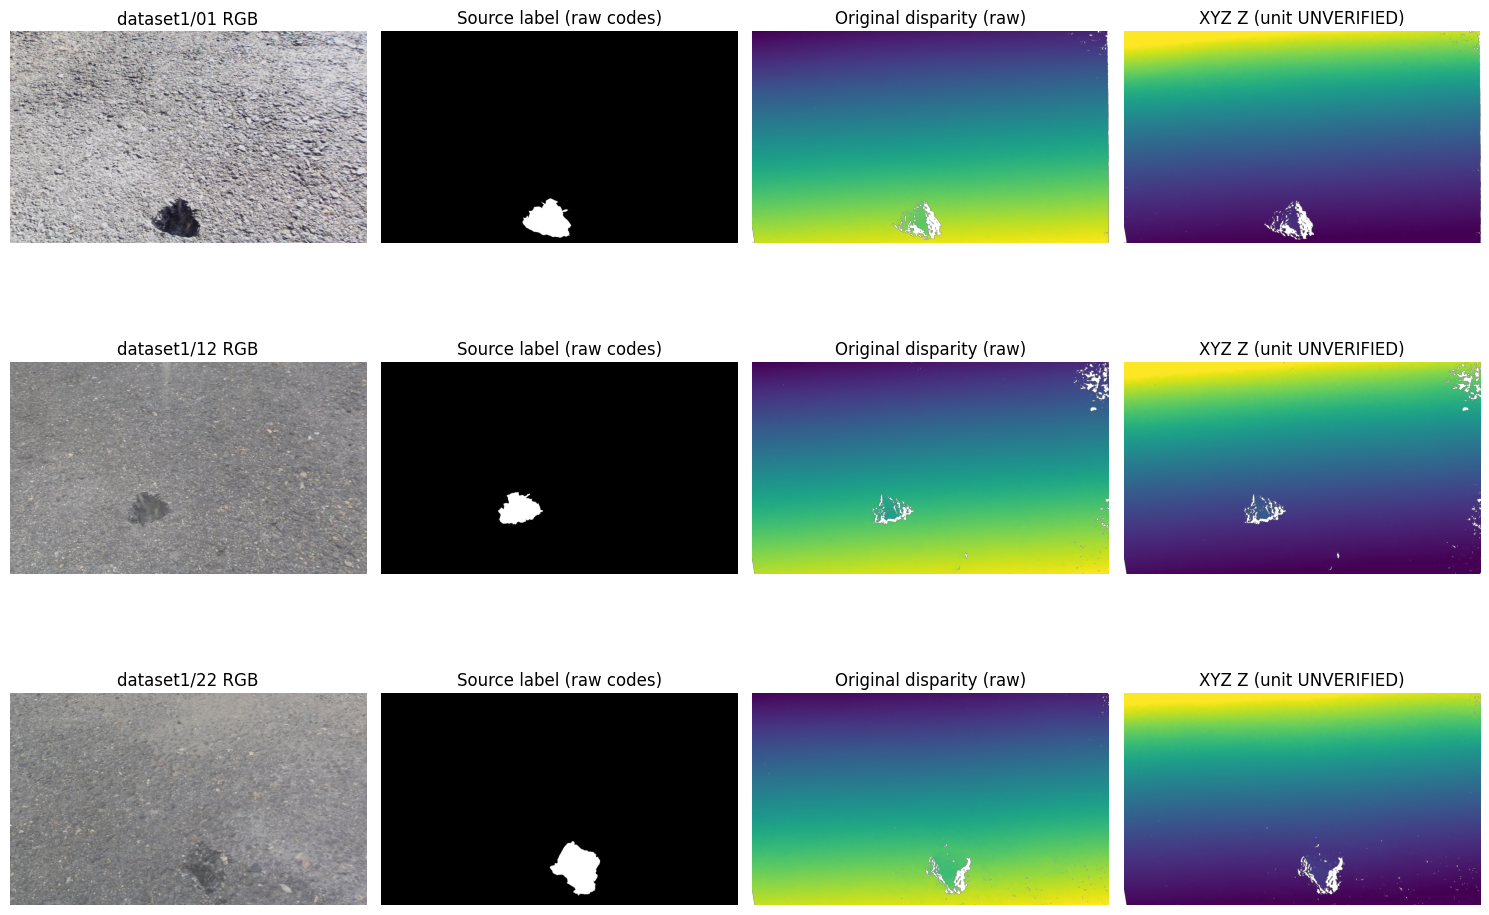


C3-09 SECTION 5 — FAN XYZ / DISPARITY AUDIT
Development frame inventory: 27
Sampled frames: 6
Internal consistency checks completed: 6
dataset1/01 | INTERNAL_STEREO_DIAGNOSTIC_COMPUTED | valid=0.991 | fX=1381.7506090470724 | B(raw)=119.43809339652191 | MAD(dZ)=0.0
dataset1/12 | INTERNAL_STEREO_DIAGNOSTIC_COMPUTED | valid=0.990 | fX=1381.7506090470724 | B(raw)=119.43809339652191 | MAD(dZ)=0.0
dataset1/22 | INTERNAL_STEREO_DIAGNOSTIC_COMPUTED | valid=0.993 | fX=1381.7506090470722 | B(raw)=119.43809339652194 | MAD(dZ)=0.0
dataset3/01 | INTERNAL_STEREO_DIAGNOSTIC_COMPUTED | valid=0.995 | fX=1389.1618424037588 | B(raw)=119.49310301530014 | MAD(dZ)=0.0
dataset3/03 | INTERNAL_STEREO_DIAGNOSTIC_COMPUTED | valid=0.983 | fX=1389.1618424037576 | B(raw)=119.49310301530024 | MAD(dZ)=0.0
dataset3/05 | INTERNAL_STEREO_DIAGNOSTIC_COMPUTED | valid=0.986 | fX=1389.161842403758 | B(raw)=119.49310301530019 | MAD(dZ)=0.0

Original 2019 physical XYZ units verified: NO
External physical measurement validati

In [9]:
# ================================================================
# CRDL COMPONENT 3 | C3-09 SECTION 5
# FAN STEREO XYZ–DISPARITY CONSISTENCY AUDIT
#
# Development-only: dataset1 + dataset3.
# Never inspect dataset2.
#
# Read-only sources | CPU | No training
# No physical-unit claims
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.io import loadmat
from PIL import Image

import numpy as np
import matplotlib.pyplot as plt

import hashlib
import json
import csv
import uuid


# ================================================================
# 1. VERIFY ENVIRONMENT
# ================================================================

assert all(
    k in globals()
    for k in ('RAW', 'OUT', 'PROJECT')
), 'Run C3-09 Section 0 first.'

FAN5 = (
    Path(RAW)
    / 'fan_stereo_pothole'
    / 'stereo_pothole_datasets-master'
)

assert FAN5.is_dir(), (
    f'Missing Fan source: {FAN5}'
)

assert Path(OUT).is_dir()


# ================================================================
# 2. CREATE VERSIONED OUTPUT DIRECTORY
# ================================================================

FAN5_OUT = Path(OUT) / (

    'section5_fan_xyz_disparity_'

    + datetime.now(
        timezone.utc
    ).strftime('%Y%m%dT%H%M%SZ_')

    + uuid.uuid4().hex[:6]
)

FAN5_OUT.mkdir(
    parents=True,
    exist_ok=False
)


# ================================================================
# 3. REUSABLE REPRODUCIBILITY HELPERS
# ================================================================

def sha256_file(p):

    h = hashlib.sha256()

    with Path(p).open('rb') as f:

        for buf in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(buf)

    return h.hexdigest()


def save_json(name, obj):

    (FAN5_OUT / name).write_text(

        json.dumps(
            obj,
            indent=2,
            default=str
        ),

        encoding='utf-8'
    )


def save_csv(name, rows):

    if not rows:
        return

    cols = sorted({
        k
        for row in rows
        for k in row
    })

    with (
        FAN5_OUT / name
    ).open(
        'w',
        newline='',
        encoding='utf-8'
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=cols
        )

        writer.writeheader()
        writer.writerows(rows)


# ================================================================
# 4. INVENTORY ALLOWED FAN FRAMES
# ================================================================

# Exact permitted development roots.
# Dataset2 is deliberately omitted.

allowed = (
    'dataset1',
    'dataset3'
)

manifest = []
selected = []

for split in allowed:

    root = FAN5 / split

    assert root.is_dir(), (
        f'Missing permitted split: {root}'
    )

    frame_files = sorted(
        (root / 'ptcloud').glob('*.mat')
    )

    frame_ids = [

        p.stem

        for p in frame_files

        if p.stem.isdigit()
    ]

    assert frame_ids, (
        f'No XYZ MAT files in {split}'
    )

    print(
        f'{split}: {len(frame_ids)} XYZ files, '
        f'frames {frame_ids[:3]} ... '
        f'{frame_ids[-3:]}'
    )

    for fid in frame_ids:

        paths = {

            'xyz':
                root / 'ptcloud'
                / (fid + '.mat'),

            'disparity':
                root / 'disp'
                / (fid + '.mat'),

            'rgb':
                root / 'rgb'
                / (fid + '.png'),

            'label':
                root / 'label'
                / (fid + '.png')
        }

        manifest.append({

            'dataset': split,

            'frame': fid,

            **{

                k + '_exists':
                    p.is_file()
                    and not p.is_symlink()

                for k, p in paths.items()
            }
        })

    # Deterministic limited QA.
    # Beginning, middle and end.
    for pos in sorted({

        0,

        len(frame_ids) // 2,

        len(frame_ids) - 1
    }):

        selected.append((
            split,
            frame_ids[pos]
        ))


save_csv(
    'allowed_frame_presence_manifest.csv',
    manifest
)

print(
    '\nFrame records inventoried:',
    len(manifest)
)

print(
    'QA frames selected:',
    selected
)


# ================================================================
# 5. LOAD RGB, XYZ AND ORIGINAL DISPARITY
# ================================================================

rows = []
figures = []

for split, fid in selected:

    root = FAN5 / split

    paths = {

        'xyz':
            root / 'ptcloud'
            / (fid + '.mat'),

        'disparity':
            root / 'disp'
            / (fid + '.mat'),

        'rgb':
            root / 'rgb'
            / (fid + '.png'),

        'label':
            root / 'label'
            / (fid + '.png')
    }

    rec = {

        'dataset':
            split,

        'frame':
            fid,

        'status':
            'INSPECTING',

        'units_status':
            'UNVERIFIED',

        'metric_training_approved':
            False
    }

    try:

        assert all(

            p.is_file()
            and not p.is_symlink()

            for p in paths.values()

        ), 'Some frame modalities missing'

        # Original Fan demo.m uses these MAT keys.
        xyz_content = loadmat(
            paths['xyz']
        )

        disp_content = loadmat(
            paths['disparity']
        )

        rec['xyz_mat_keys'] = sorted(

            k for k in xyz_content

            if not k.startswith('__')
        )

        rec['disp_mat_keys'] = sorted(

            k for k in disp_content

            if not k.startswith('__')
        )

        if (

            'xyzPoints' not in xyz_content

            or 'disp' not in disp_content
        ):

            raise ValueError(
                'Expected xyzPoints and disp '
                'MAT variables not present'
            )

        xyz = np.asarray(
            xyz_content['xyzPoints']
        )

        disp = np.asarray(
            disp_content['disp']
        ).squeeze()

        with Image.open(
            paths['rgb']
        ) as im:

            rgb = np.asarray(
                im.convert('RGB')
            )

        with Image.open(
            paths['label']
        ) as im:

            label = np.asarray(
                im.convert('L')
            )

        # -----------------------------------------
        # Array dimensions
        # -----------------------------------------

        if (

            xyz.ndim != 3

            or xyz.shape[-1] != 3

            or disp.ndim != 2
        ):

            raise ValueError(

                f'Unexpected array dimensions: '
                f'xyz={xyz.shape}, '
                f'disparity={disp.shape}'
            )

        rec['xyz_shape'] = list(
            xyz.shape
        )

        rec['disp_shape'] = list(
            disp.shape
        )

        rec['rgb_shape'] = list(
            rgb.shape
        )

        rec['label_shape'] = list(
            label.shape
        )

        assert (

            xyz.shape[:2]
            == disp.shape
            == label.shape
            == rgb.shape[:2]

        ), 'Spatial shapes differ across modalities'

        # -----------------------------------------
        # Extract 3D coordinates
        # -----------------------------------------

        H, W = disp.shape

        X, Y, Z = (

            xyz[..., i].astype(
                np.float64,
                copy=False
            )

            for i in range(3)
        )

        D = disp.astype(
            np.float64,
            copy=False
        )

        # -----------------------------------------
        # Valid sensor geometry
        # -----------------------------------------

        good = (

            np.isfinite(X)

            & np.isfinite(Y)

            & np.isfinite(Z)

            & np.isfinite(D)

            & (Z > 0)

            & (D > 0)
        )

        rec[
            'valid_xyz_disp_fraction'
        ] = float(
            good.mean()
        )

        total = int(
            good.sum()
        )

        if total < 1000:

            raise ValueError(

                'Insufficient positive finite '
                f'XYZ/disparity matches: {total}'
            )

        # -----------------------------------------
        # Deterministic bounded sampling
        # -----------------------------------------

        flat_idx = np.flatnonzero(
            good
        )

        if len(flat_idx) > 25000:

            rng = np.random.default_rng(

                20261021

                + (
                    1 if split == 'dataset3'
                    else 0
                )

                + int(fid)
            )

            flat_idx = rng.choice(

                flat_idx,

                size=25000,

                replace=False
            )

        v, u = np.unravel_index(

            flat_idx,

            D.shape
        )

        xs = X[v, u]
        ys = Y[v, u]
        zs = Z[v, u]
        ds = D[v, u]

        # ====================================================
        # 6. STEREO DISPARITY–DEPTH CONSISTENCY
        # ====================================================

        # Z = fB/d
        # Therefore dZ = fB
        #
        # Units here remain UNKNOWN.
        # Stable dZ is not proof of mm.

        fb = ds * zs

        med_fb = float(
            np.median(fb)
        )

        mad_fb = float(

            np.median(

                np.abs(
                    fb - med_fb
                )
            )
        )

        rec[
            'median_disparity_times_Z_raw_px'
        ] = med_fb

        rec[
            'relative_MAD_disparity_Z'
        ] = float(

            mad_fb
            / (abs(med_fb) + 1e-12)
        )

        rec[
            'median_Z_RAW_UNITS'
        ] = float(
            np.median(zs)
        )

        rec[
            'median_disparity_RAW'
        ] = float(
            np.median(ds)
        )

        # ====================================================
        # 7. PINHOLE CAMERA PROJECTION DIAGNOSTIC
        # ====================================================

        # X/Z = (u-cx)/fx
        # Y/Z = (v-cy)/fy
        #
        # Regress observed XYZ ratios against
        # pixel coordinates.
        #
        # This estimates effective geometry
        # from the existing reconstruction.
        # It is not independent calibration.

        def affine_fit(t, r):

            A = np.column_stack((

                t.astype(np.float64),

                np.ones(t.size)
            ))

            a, b = np.linalg.lstsq(

                A,

                r,

                rcond=None

            )[0]

            pred = a * t + b

            denom = np.sum(

                (r - np.mean(r)) ** 2
            )

            r2 = 1.0 - float(

                np.sum(
                    (r - pred) ** 2
                )

                / (denom + 1e-12)
            )

            return (
                float(a),
                float(b),
                r2
            )

        ax, bx, r2x = affine_fit(

            u,

            xs / zs
        )

        ay, by, r2y = affine_fit(

            v,

            ys / zs
        )

        rec['projection_x_r2'] = r2x
        rec['projection_y_r2'] = r2y

        rec['effective_fx_abs_px'] = (

            float(
                abs(1 / ax)
            )

            if abs(ax) > 1e-12

            else None
        )

        rec['effective_fy_abs_px'] = (

            float(
                abs(1 / ay)
            )

            if abs(ay) > 1e-12

            else None
        )

        rec[
            'effective_projection_x_sign'
        ] = int(
            np.sign(ax)
        )

        rec[
            'effective_projection_y_sign'
        ] = int(
            np.sign(ay)
        )

        # ====================================================
        # 8. INFER NUMERICAL BASELINE HYPOTHESIS
        # ====================================================

        # B = median(dZ) / effective_fx
        #
        # This is an internal geometry diagnostic.
        # The XYZ physical units remain unknown.

        rec[
            'baseline_in_XYZ_RAW_UNITS_HYPOTHESIS'
        ] = (

            float(

                med_fb

                / rec['effective_fx_abs_px']
            )

            if rec['effective_fx_abs_px']

            else None
        )

        rec['status'] = (
            'INTERNAL_STEREO_DIAGNOSTIC_COMPUTED'
        )

        # -----------------------------------------
        # Source integrity
        # -----------------------------------------

        for key, p in paths.items():

            rec[
                f'{key}_sha256'
            ] = sha256_file(p)

        # Preserve three examples for visualization.
        if len(figures) < 3:

            figures.append((

                split,
                fid,
                rgb,
                label,
                D,
                Z,
                good
            ))

    except Exception as exc:

        rec['status'] = 'REVIEW_ERROR'

        rec['error'] = (

            f'{type(exc).__name__}: '

            + str(exc)[:180]
        )

    rows.append(rec)


# ================================================================
# 9. SAVE NUMERICAL DIAGNOSTICS
# ================================================================

save_csv(

    'fan_sample_xyz_disparity_diagnostics.csv',

    rows
)

save_json(

    'fan_sample_xyz_disparity_diagnostics.json',

    rows
)


# ================================================================
# 10. VISUALIZE SOURCE RGB, LABEL, DISPARITY, XYZ
# ================================================================

if figures:

    fig, axes = plt.subplots(

        len(figures),

        4,

        figsize=(
            15,
            3.6 * len(figures)
        ),

        squeeze=False
    )

    for i, (
        split,
        fid,
        rgb,
        label,
        disp,
        z,
        good
    ) in enumerate(figures):

        axes[i, 0].imshow(
            rgb
        )

        axes[i, 0].set_title(
            f'{split}/{fid} RGB'
        )

        axes[i, 1].imshow(

            label,

            cmap='gray'
        )

        axes[i, 1].set_title(
            'Source label (raw codes)'
        )

        axes[i, 2].imshow(

            np.ma.masked_where(
                ~good,
                disp
            ),

            cmap='viridis'
        )

        axes[i, 2].set_title(
            'Original disparity (raw)'
        )

        lo, hi = np.percentile(

            z[good],

            [2, 98]
        )

        axes[i, 3].imshow(

            np.ma.masked_where(
                ~good,
                z
            ),

            cmap='viridis',

            vmin=lo,

            vmax=max(
                hi,
                lo + 1
            )
        )

        axes[i, 3].set_title(
            'XYZ Z (unit UNVERIFIED)'
        )

        for ax in axes[i]:
            ax.axis('off')

    plt.tight_layout()

    plt.savefig(

        FAN5_OUT /
        'fan_rgb_label_disp_xyz_preview.png',

        dpi=135,

        bbox_inches='tight'
    )

    plt.show()

    plt.close(fig)


# ================================================================
# 11. SAVE PHYSICAL CALIBRATION DECISION
# ================================================================

summary = {

    'stage':
        'C3-09_SECTION5_FAN_INTERNAL_STEREO',

    'allowed_sources': [

        'Fan pothole dataset1',

        'Fan pothole dataset3'
    ],

    'protected_dataset2_inspected':
        False,

    'frame_presence_records':
        len(manifest),

    'sampled_frames':
        len(rows),

    'completed_internal_checks':

        sum(

            r['status']
            == 'INTERNAL_STEREO_DIAGNOSTIC_COMPUTED'

            for r in rows
        ),

    'published_2018_ZED_baseline_mm':
        120.0,

    'published_2018_baseline_is_2019_calibration_proof':
        False,

    'original_2019_pothole_intrinsics_verified':
        False,

    'original_2019_pothole_XYZ_units_verified':
        False,

    'independent_metric_accuracy_test_completed':
        False,

    'metric_training_authorized':
        False,

    'note':
        'Self-consistency of XYZ/disparity '
        'can hold under arbitrary shared '
        'scale; it cannot establish physical '
        'units or external accuracy.'
}


save_json(

    'fan_source_scale_gate.json',

    summary
)


# ================================================================
# 12. CREATE CHECKSUM MANIFEST
# ================================================================

receipts = []

for p in sorted(
    FAN5_OUT.iterdir()
):

    if (
        p.is_file()

        and p.name != 'sha256_manifest.json'
    ):

        receipts.append({

            'filename':
                p.name,

            'sha256':
                sha256_file(p),

            'bytes':
                p.stat().st_size
        })


save_json(

    'sha256_manifest.json',

    receipts
)


# ================================================================
# 13. PRINT FINAL RESEARCH RESULTS
# ================================================================

print("\n" + "=" * 70)

print(
    "C3-09 SECTION 5 — FAN XYZ / DISPARITY AUDIT"
)

print("=" * 70)

print(
    "Development frame inventory:",
    len(manifest)
)

print(
    "Sampled frames:",
    len(rows)
)

print(
    "Internal consistency checks completed:",
    summary['completed_internal_checks']
)

for r in rows:

    print(

        f"{r['dataset']}/{r['frame']} "

        f"| {r['status']} "

        f"| valid="
        f"{r.get('valid_xyz_disp_fraction', float('nan')):.3f} "

        f"| fX="
        f"{r.get('effective_fx_abs_px')} "

        f"| B(raw)="
        f"{r.get('baseline_in_XYZ_RAW_UNITS_HYPOTHESIS')} "

        f"| MAD(dZ)="
        f"{r.get('relative_MAD_disparity_Z')}"
    )

    if 'error' in r:

        print(
            '  ERROR:',
            r['error']
        )


print(
    "\nOriginal 2019 physical XYZ units verified: NO"
)

print(
    "External physical measurement validation completed: NO"
)

print(
    "Physically metric training authorized: NO"
)

print(
    "Protected Fan dataset2 inspected: NO"
)

print("\nSaved:", FAN5_OUT)

print("=" * 70)